# Competitive Analysis of Automobile Discussions
### Analytics of Unstructured Data · Group Assignment 1 · Tasks A–G

**Team members:** Isha Singh, Daksh M. Prajapati, Yixuan Chen, Ava Thomas, and Hemanth Katragadda  
**Client:** J.D. Power and Associates  
**Dataset:** `sample_data.csv`

This project examines which automobile brands and product attributes appear most often in the forum discussions, which brands are mentioned together more often than expected, and what those patterns may mean for J.D. Power and its clients. The results describe conversation in this dataset. They should not be interpreted as market share, customer preference, sentiment, or proof that two brands directly compete.

## Project workflow

We completed the analysis in seven stages.

### Data preparation

We first loaded the headerless CSV, named its three fields, and checked it with both Python's CSV reader and pandas. Stable post IDs were then assigned so that every decision could be traced back to the source. Nine empty posts and five additional nonempty duplicate records were removed, leaving 5,986 posts. Short replies and posts with no selected brand were kept because they are still part of the discussion population.

The original text was preserved. A separate analysis version removed one clearly systematic quote-related `kia hyundai` insertion and normalized whitespace. Ambiguous date labels were not converted into calendar dates. We also measured author concentration and post length before starting the main analysis.

### Task A: important brands and attributes

We used TF–IDF and NMF topic discovery across the full retained corpus to find recurring words, phrases, model-like terms, and discussion themes. After inspecting examples in context, we created a corpus-based list of brand aliases and product attributes. Clear text-corruption fragments were masked only in the matching version of the text. Each brand or attribute counted at most once per post. We compared the main ranking with alternative preprocessing choices and unique-author reach, tested the rules on small examples, and exported posts for independent review.

### Task B: lexical brand lift

The ten most frequently mentioned brands from Task A were fixed for the remaining analysis. For each retained post, we recorded whether each brand appeared and calculated post-level co-occurrence and lift. An eight-post example was used to verify the formula by hand. We also checked how the results changed when fragment exclusions were removed and when the ten most active usernames were excluded.

### Task C: LLM-based attribution

The notebook includes a structured and cached LLM workflow intended to classify all retained posts using the same top-ten brand list. It validates post IDs and evidence spans, records model usage and cost, and compares semantic results with the lexical baseline. The saved run returned 5,186 of 5,986 posts (86.6% coverage), so its semantic lift and downstream comparison should be treated as provisional rather than as a completed full-population result.

### Task D: competitive structure

Brand association was converted into normalized PMI and then into a bounded distance. Metric multidimensional scaling (MDS) produced a two-dimensional map, and hierarchical clustering added group labels. Lexical and provisional semantic maps were compared to see whether the overall structure was sensitive to the measurement method.

### Task E: brand–attribute positioning

For the five leading brands and attributes, each attribute occurrence was assigned to the only brand in its sentence or to the uniquely nearest brand when several appeared. Tied or distant cases were left unassigned. Lift and support were then calculated over brand–post units, and a review sample was exported.

### Task F: aspiration

Aspiration was defined narrowly as a first-person, forward-looking intention or desire to acquire a vehicle. Negated intent, past or current ownership alone, praise, and recommendations to other people were excluded. We compared both the number of qualifying posts and the rate per brand mention, with a minimum support rule for selecting a winner.

### Task G: recommendations

Finally, we combined the competitive map, brand–attribute associations, and aspiration results. Each recommendation is tied to numerical evidence and a confidence level so that strong descriptive findings are separated from results that still require manual validation.

In [ ]:
from google.colab import files

print("Please upload the 'sample_data.csv' file.")
uploaded = files.upload()

Please upload the 'sample_data.csv' file.


Saving sample_data.csv to sample_data.csv


In [ ]:
from pathlib import Path
import sys, re, csv, io, json, hashlib, html, random, importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from IPython.display import display, Markdown, HTML

SEED = 20260915
TEAM_MEMBERS = ['Isha Singh', 'Daksh M Prajapati', 'Yixuan Chen', 'Ava Thomas' , 'Hemanth Katragadda']
ROOT = Path.cwd()
OUT = ROOT / 'results' / 'task_ag'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_columns', 16)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
versions = {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'matplotlib', 'scikit-learn']}
print('Python:', sys.version.split()[0], '| Packages:', versions)
print('Team:', ', '.join(TEAM_MEMBERS))
def show_full_table(table):
    display(HTML(table.to_html(index=False, escape=True)))

Python: 3.13.15 | Packages: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'scikit-learn': '1.6.1'}
Team: Isha Singh, Daksh M Prajapati, Yixuan Chen, Ava Thomas, Hemanth Katragadda


## Data preparation and audit

### Source structure and exclusions

The source file has no header, and each row contains a username, a date label, and the text of one forum post. We assigned a stable ID to every row and confirmed that Python's CSV reader and pandas produced the same 6,000 records and 18,000 field values.

An exact duplicate was defined as a repeated combination of username, date label, and raw text. We kept the first copy, removed nine empty posts and five additional nonempty duplicates, and retained 5,986 posts. This prevents identical records from receiving extra weight. We did not deduplicate on text alone because two users can independently write the same short reply. Nonempty short posts and no-brand posts remain in the dataset and, where appropriate, in the denominator.

In [ ]:
SOURCE = ROOT / 'sample_data.csv'
source_bytes = SOURCE.read_bytes()
source_sha256 = hashlib.sha256(source_bytes).hexdigest()
EXPECTED_SHA256 = '1af81f6b88bec9ae0bf1cf668eaefdee86cc69b5ad27d3d74a797ab4a7991bad'
assert source_sha256 == EXPECTED_SHA256, 'Source changed; repeat the audit before applying cached semantic decisions.'
rows = list(csv.reader(io.StringIO(source_bytes.decode('utf-8-sig'), newline=''), strict=True))
assert all(len(row) == 3 for row in rows)
raw = pd.read_csv(SOURCE, header=None, names=['username', 'date_raw', 'text_raw'],
                  dtype=str, keep_default_na=False, encoding='utf-8')
assert raw.values.tolist() == rows, 'Independent parsers disagree.'
raw.insert(0, 'post_id', [f'post_{i:06d}' for i in range(1, len(raw) + 1)])
empty = raw.text_raw.str.strip().eq('')
duplicate = raw.duplicated(['username', 'date_raw', 'text_raw'], keep='first')
raw['exclusion_reason'] = np.select([empty, duplicate], ['empty_text', 'exact_duplicate_record'], default='')
raw['eligible'] = raw.exclusion_reason.eq('')
posts = raw.loc[raw.eligible].copy().set_index('post_id')
N = len(posts)
audit_table = pd.DataFrame({
    'Measure': ['Original records', 'Fields per record', 'Missing usernames', 'Missing dates',
                'Empty posts excluded', 'Duplicate copies including empty repeats',
                'Additional nonempty duplicates excluded', 'Retained posts', 'Distinct usernames'],
    'Value': [len(raw), 3, raw.username.str.strip().eq('').sum(), raw.date_raw.str.strip().eq('').sum(),
              empty.sum(), duplicate.sum(), (duplicate & ~empty).sum(), N, posts.username.nunique()]
})
assert len(raw) == N + empty.sum() + (duplicate & ~empty).sum()
assert (len(raw), N) == (6000, 5986)
display(audit_table)
display(raw.loc[~raw.eligible, ['post_id', 'username', 'date_raw', 'exclusion_reason']])
print('Source SHA-256:', source_sha256)

,Measure,Value
0,Original records,6000
1,Fields per record,3
2,Missing usernames,0
3,Missing dates,0
4,Empty posts excluded,9
5,Duplicate copies including empty repeats,8
6,Additional nonempty duplicates excluded,5
7,Retained posts,5986
8,Distinct usernames,329


,post_id,username,date_raw,exclusion_reason
1181,post_001182,dhamilton,6-Dec,empty_text
1854,post_001855,qbrozen,7-Feb,exact_duplicate_record
1857,post_001858,blueguydotcom,7-Feb,exact_duplicate_record
3208,post_003209,fedlawman,7-Apr,empty_text
3209,post_003210,blueguydotcom,7-Apr,empty_text
3211,post_003212,wale_bate1,7-Apr,empty_text
3876,post_003877,readerreader,7-Sep,empty_text
3878,post_003879,readerreader,7-Sep,empty_text
3879,post_003880,readerreader,7-Sep,empty_text
3881,post_003882,readerreader,7-Sep,empty_text


Source SHA-256: 1af81f6b88bec9ae0bf1cf668eaefdee86cc69b5ad27d3d74a797ab4a7991bad


### Cleaning a systematic quote artifact

The source audit found 5,957 instances of `kia hyundai` immediately after a quotation mark, spread across 1,697 retained posts. The phrase appeared after ordinary quoted words as well as inch measurements, which strongly suggests a systematic insertion error rather than thousands of genuine brand references. Before cleanup, the token `kia` appeared in 1,710 posts and `hyundai` in 1,792; after removing only this quote-linked sequence, those counts fell to 27 and 157.

We therefore removed that exact pattern from a separate analysis field while leaving the raw text unchanged. The procedure keeps the quotation marks and only normalizes whitespace. Punctuation, negation, raw date labels, URLs, and HTML entities are otherwise preserved at this stage. Later matching rules remove URL spans and decode HTML entities in another derived field, so the original evidence is always available.

In [ ]:
QUOTE_ARTIFACT = re.compile(r'"\s+kia\s+hyundai\b', re.I)
def normalize_space(text):
    return re.sub(r'\s+', ' ', text).strip()
def remove_quote_artifact(text):
    return normalize_space(QUOTE_ARTIFACT.sub('"', text))

posts['text_normalized'] = posts.text_raw.map(normalize_space)
posts['text_quote_clean'] = posts.text_raw.map(remove_quote_artifact)
quote_occurrences = posts.text_raw.map(lambda t: len(QUOTE_ARTIFACT.findall(t))).sum()
quote_posts = posts.text_raw.str.contains(QUOTE_ARTIFACT).sum()
assert quote_occurrences == 5957 and quote_posts == 1697
assert all(a.count('"') == b.count('"') for a, b in zip(posts.text_raw, posts.text_quote_clean))
assert posts.text_quote_clean.map(remove_quote_artifact).equals(posts.text_quote_clean)
display(pd.DataFrame({
    'Literal token': ['kia', 'hyundai'],
    'Posts before quote cleanup': [posts.text_normalized.str.contains(r'\b'+t+r'\b', case=False).sum() for t in ['kia','hyundai']],
    'Posts after quote cleanup': [posts.text_quote_clean.str.contains(r'\b'+t+r'\b', case=False).sum() for t in ['kia','hyundai']]
}))
display(posts.loc[['post_000304', 'post_000013'], ['text_normalized', 'text_quote_clean']])

,Literal token,Posts before quote cleanup,Posts after quote cleanup
0,kia,1710,27
1,hyundai,1792,157


,text_normalized,text_quote_clean
post_id,,
post_000304,"not so much "" kia hyundai guinea pig "" kia hyundai with a quality company like bmw but a qa run for the la...","not so much "" guinea pig "" with a quality company like bmw but a qa run for the larger engine runs "" down ..."
post_000013,""" kia hyundai otoh, like i toyota d they don't do it for me. "" kia hyundai got it. so what car in here app...",""" otoh, like i toyota d they don't do it for me. "" got it. so what car in here appeals to you and why? you..."


### Dates, author concentration, and post length

The dataset contains 44 date labels ranging from `6-Oct` to `11-Nov`, with sequences such as `6-Dec` followed by `7-Jan`.

The corpus is also concentrated among a small number of contributors. The ten most active usernames wrote 2,810 posts, or 46.94% of the retained dataset. The median post contains 64 whitespace-separated words, although 113 posts contain fewer than five words; no minimum-length filter was applied. Because usernames are not verified individuals and quoted material may repeat earlier opinions, the results measure forum activity rather than independent consumer responses. Unique-author reach is reported as a sensitivity check.

In [ ]:
author_counts = posts.username.value_counts()
lengths = posts.text_quote_clean.str.split().str.len()
display(pd.DataFrame({'posts': author_counts.head(10), 'share_percent': (100 * author_counts.head(10) / N).round(2)}))
display(lengths.describe(percentiles=[.25, .5, .75, .95, .99]).rename('Whitespace words').to_frame().round(1))
print(f'Distinct date labels: {posts.date_raw.nunique()}')
print(f'Top ten usernames: {author_counts.head(10).sum():,} posts ({100*author_counts.head(10).sum()/N:.2f}%).')
print(f'Posts under five words: {(lengths < 5).sum()}; no minimum-length filter is applied.')

,posts,share_percent
username,,
blueguydotcom,556,9.29
circlew,359,6.00
louiswei,328,5.48
kdshapiro,307,5.13
fedlawman,276,4.61
rockylee,253,4.23
plekto,217,3.63
shipo,193,3.22
habitat1,189,3.16


,Whitespace words
count,5986.0
mean,97.3
std,105.4
min,1.0
25%,30.0
50%,64.0
75%,126.8
95%,300.0
99%,503.6
max,1295.0


Distinct date labels: 44
Top ten usernames: 2,810 posts (46.94%).
Posts under five words: 113; no minimum-length filter is applied.


## Task A — Identify important brands and product attributes

**Question:** Without relying on a supplied brand/model dictionary, which automobile
brands and product attributes actually dominate this forum's conversation, and how
should "important" be defined and operationalized so the resulting ranking is
defensible rather than arbitrary? The answer matters beyond Task A itself: the ten
brands and five attributes selected here are **frozen and reused** as the fixed
universe for every subsequent task (B through G), so an unreliable or narrowly
defined ranking here would propagate downstream rather than staying contained to
this section.

### A1. Discovery approach

We did not begin with a ready-made automobile dictionary. Instead, we searched the full retained corpus for recurring words, phrases, and model-like forms. TF–IDF was used to measure document-level prominence, and non-negative matrix factorization (NMF) was used to reveal groups of terms that tended to occur in similar posts. The NMF topics were used as discovery aids, not as a claim that the corpus contains exactly twelve true topics.

The main TF–IDF model used `min_df=5`, meaning that a term had to appear in at least five posts. This reduced one-off misspellings and damaged fragments while still retaining recurring aliases. We did not impose an upper document-frequency limit because no post-stopword term was common enough to require one. Candidate terms and examples were then reviewed in context to distinguish brands, parent companies, model aliases, attributes, and obvious source corruption.

The final alias and attribute rules were applied deterministically to all 5,986 posts. A brand or attribute counts once per post even if it is repeated many times. Automated steps include candidate extraction, topic fitting, matching, counting, and sensitivity checks. Human or LLM-assisted judgment is still needed when deciding whether an expression is a brand, which company owns a model alias, and whether damaged text is interpretable.

We considered generic named-entity recognition, but it would likely miss lowercase model codes and struggle with the corrupted text. Raw token counts were also rejected because repeated substitutions could dominate the ranking. Sentiment is outside the definition of importance used here.

In [ ]:
# General English stopwords affect discovery only, never the brand mention denominator.
discovery_stop = sorted(set(ENGLISH_STOP_WORDS) | set('''car cars really just like think know don ve ll im does doesn didn isn aren wasn won wouldn could couldn should actually going got make say said want thing things way people time years year new good better best lot sure right regards ow rocky shipo'''.split()))
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=5, max_df=1.0, max_features=7000,
    sublinear_tf=True, stop_words=discovery_stop,
    token_pattern=r'(?u)\b[a-z0-9][a-z0-9-]+\b')
tfidf = vectorizer.fit_transform(posts.text_quote_clean)
vocabulary = vectorizer.get_feature_names_out()
candidate_table = pd.DataFrame({'candidate': vocabulary,
    'post_frequency': np.asarray((tfidf > 0).sum(axis=0)).ravel(),
    'mean_tfidf': np.asarray(tfidf.mean(axis=0)).ravel()})
candidate_table = candidate_table.sort_values(['post_frequency', 'candidate'], ascending=[False, True])
nmf = NMF(n_components=12, init='nndsvda', random_state=SEED, max_iter=400)
topic_weights = nmf.fit_transform(tfidf)
topic_table = pd.DataFrame([
    {'topic': i + 1, 'top_terms': ', '.join(vocabulary[np.argsort(weights)[-12:][::-1]])}
    for i, weights in enumerate(nmf.components_)])
display(candidate_table.head(25).round({'mean_tfidf': 4}))
show_full_table(topic_table)
print(f'NMF fitted to {tfidf.shape[0]:,} posts and {tfidf.shape[1]:,} terms; {nmf.n_iter_} iterations.')
assert nmf.n_iter_ < nmf.max_iter, 'NMF reached its iteration limit; inspect convergence.'

,candidate,post_frequency,mean_tfidf
1192,bmw,2013,0.0292
6435,toyota,1678,0.0230
640,acura,775,0.0155
912,audi,769,0.0151
2334,drive,748,0.0118
6366,tl,738,0.0148
5588,sedan,715,0.0125
3268,honda,713,0.0124
4740,performance,662,0.0112
4042,luxury,636,0.0113


topic,top_terms
1,"mercedes-benz, mercedes-benz benz, benz, benz mercedes-benz, bmw mercedes-benz, lexus, class, bmw, benz bmw, luxury, mb, reliable"
2,"bmw, bmw bmw, series, hp, cts-v, e46, lexus, coupe, vs, is350, 335, performance"
3,"sedan, luxury, performance, entry, level, entry level, performance sedan, luxury performance, level luxury, luxury sedan, entry-level, sports"
4,"acura, tl, honda, acura tl, infiniti, acura acura, lexus, nissan, tl acura, great, sh-awd, v6"
5,"com, http, www, http www, edmunds, edmunds com, www edmunds, html, insideline, com insideline, articleid, com reviews"
6,"cts, pontiac, interior, looks, cadillac, gm, nice, series, look, seat, 08, class"
7,"toyota, honda, ellps, toyota ed, lexus, ed, able, toyota toyota, driving, seat, toyota able, nissan"
8,"tires, awd, rwd, snow, winter, drive, fwd, driving, winter tires, wheels, weight, need"
9,"audi, volvo, volkswagen, audi audi, volvo volvo, saab, 0t, drive, driven, audi 0t, mazda, is250"
10,"manual, transmission, manual transmission, automatic, sport, package, tranny, stick, seat, option, manual tranny, leather"


NMF fitted to 5,986 posts and 7,000 terms; 131 iterations.


### A1b. Sensitivity of the document-frequency threshold

Because `min_df` is an analyst choice, we compared the selected value of 5 with stricter and looser alternatives. Raising it to 8 removed 2,247 terms that survived at 5, including potentially useful model phrases. Lowering it toward 3 mainly introduced rare, noisy, or difficult-to-interpret expressions. The displayed vocabulary reaches the 7,000-feature cap for the settings of 5 and 3, so the comparison should be read as a practical feature-selection check rather than a complete inventory of every rare term. Overall, 5 offered a reasonable balance between recurring signal and noise for discovery.

In [ ]:
# Sensitivity check: compare bottom 20 terms across min_df=8, 5 (chosen), and 3
min_df_options = [8, 5, 3]
sensitivity_results = {}

for md in min_df_options:
    v = TfidfVectorizer(
        ngram_range=(1, 2), min_df=md, max_df=1.0, max_features=7000,
        sublinear_tf=True, stop_words=discovery_stop,
        token_pattern=r'(?u)\b[a-z0-9][a-z0-9-]+\b')
    tf = v.fit_transform(posts.text_quote_clean)
    vocab = v.get_feature_names_out()
    table = pd.DataFrame({
        'candidate': vocab,
        'post_frequency': np.asarray((tf > 0).sum(axis=0)).ravel(),
        'mean_tfidf': np.asarray(tf.mean(axis=0)).ravel()
    }).sort_values(['post_frequency', 'candidate'], ascending=[False, True])
    sensitivity_results[md] = table

# Side-by-side comparison of bottom 20 terms per threshold
# (i.e. the rarest terms that still survived each min_df cutoff)
comparison_table = pd.DataFrame({
    f'min_df={md} (bottom 20)': sensitivity_results[md].tail(20)['candidate'].values
    for md in min_df_options
})
print('Vocabulary sizes:', {md: len(sensitivity_results[md]) for md in min_df_options})
display(comparison_table)

# Terms unique to the lower threshold (min_df=3) vs the chosen one (min_df=5)
vocab_5 = set(sensitivity_results[5]['candidate'])
vocab_3 = set(sensitivity_results[3]['candidate'])
new_at_3 = sorted(vocab_3 - vocab_5)
print(f'\n{len(new_at_3)} term(s) appear only when min_df drops from 5 to 3:')
display(sensitivity_results[3][sensitivity_results[3]['candidate'].isin(new_at_3)]
        .sort_values('post_frequency', ascending=False).head(30))

# Terms lost by raising the threshold from 5 to 8
vocab_8 = set(sensitivity_results[8]['candidate'])
lost_at_8 = sorted(vocab_5 - vocab_8)
print(f'\n{len(lost_at_8)} term(s) present at min_df=5 but excluded at min_df=8:')
display(sensitivity_results[5][sensitivity_results[5]['candidate'].isin(lost_at_8)]
        .sort_values('post_frequency', ascending=False).head(30))

Vocabulary sizes: {8: 4753, 5: 7000, 3: 7000}


,min_df=8 (bottom 20),min_df=5 (bottom 20),min_df=3 (bottom 20)
0,vs german,whatsoever,outside mirrors
1,wall,wheels look,oven
2,wallet,widespread,photobucket
3,wanted bmw,wikipedia org,place value
4,weighing,worlds,prizm
5,wheel tire,wr,processing
6,windshield wipers,wrapped,real plastic
7,woman,writer,rear-wheel-drive
8,woods,www insideline,receives
9,world class,xk,repair replace



309 term(s) appear only when min_df drops from 5 to 3:


,candidate,post_frequency,mean_tfidf
5439,rolled,5,0.000156
5436,rofl,5,0.000270
5430,rocks,5,0.000197
1038,awd speed,5,0.000211
1033,awd great,5,0.000161
1024,awaiting,5,0.000189
1015,ave ultra,5,0.000177
1010,aux,5,0.000139
1001,automobile mag,5,0.000181
995,automatic tranny,5,0.000180



2247 term(s) present at min_df=5 but excluded at min_df=8:


,candidate,post_frequency,mean_tfidf
6966,year-old,7,0.000256
6963,yea,7,0.000304
6947,www roadandtrack,7,0.000253
6896,wire,7,0.000280
6893,winter wheels,7,0.000209
6803,warrantee,7,0.000281
6762,volkswagen cc,7,0.000250
6761,volkswagen bmw,7,0.000216
6755,visually,7,0.000226
6746,vinyl seat,7,0.000254


### What the discovery stage revealed

The most visible themes involved transmission (`manual`, `automatic`, `shifting`), driving and traction (`drive`, `AWD`, `tires`), and ownership economics (`lease`, `price`, `maintenance`). Several NMF components were dominated by brand names, URLs, or repeated damaged text, so we did not automatically treat every component as a meaningful product attribute. Final attribute frequencies come from transparent lexical rules rather than topic weights.

The TF–IDF feature set is intentionally limited, but a separate full-corpus token inventory was used to keep lower-frequency brand and model candidates available for review. The resulting mapping reflects expressions that actually occur in this dataset; it is not intended to be a complete list of every automobile brand or model.

In [ ]:
token_sets = posts.text_quote_clean.str.lower().map(lambda t: set(re.findall(r'[a-z0-9]+(?:-[a-z0-9]+)*', t)))
token_frequency = Counter(token for tokens in token_sets for token in tokens)
model_candidates = pd.DataFrame([
    {'candidate': t, 'posts': n} for t, n in token_frequency.items()
    if re.search('[a-z]', t) and re.search('[0-9]', t)
]).sort_values(['posts', 'candidate'], ascending=[False, True])
display(model_candidates.head(30))
print('Numbers such as 40k, 300hp, and 6-speed are not automatically treated as model aliases.')

,candidate,posts
28,is350,224
37,v6,149
31,330i,134
184,is250,133
25,30k,123
2,40k,109
33,e90,105
52,e46,96
66,6-speed,93
6,0t,89


Numbers such as 40k, 300hp, and 6-speed are not automatically treated as model aliases.


### A2. Handling corrupted and ambiguous text

Several brand names appear inside clearly broken words, including forms such as `con nissan tion`, `reg toyota ration`, and `c dodge ped`. Counting these strings as real brand mentions would inflate the results. For the primary analysis, we mask a small set of observed corruption patterns in the matching field only. We do not guess the original word, and the raw text remains unchanged. A second calculation without these masks shows how much the decision affects the rankings.

The frequent phrase `pontiac 5` is especially ambiguous. Examples such as “my 2004 infiniti pontiac 5” suggest that the text has been damaged, but they do not reliably identify the intended model. We therefore do not count that phrase by itself as Pontiac. An explicit Pontiac or Infiniti mention elsewhere in the same post can still count.

URL spans are excluded from brand matching because a token inside a link does not necessarily represent the author's discussion. Repeated brand text is handled by binary post-level counting, so it does not need to be deleted. Ordinary quotations remain part of the analysis.

In [ ]:
# These patterns come from observed text fragments, not a generic car dictionary.
ARTIFACT_RULES = {
    'Toyota followed by obvious fragment': r'\btoyota\s+(?:d|mics?|ably|ability|able|icated)\b',
    'Toyota embedded after observed fragment': r'\b(?:l|d|h|m|stat|cons|character|enthusa|reg|wh|soph)\s+toyota\b',
    'Nissan word fragments': r'\b(?:con|uni|re)\s+nissan\s+(?:tions?|se|l)\b|\bvice[-\s]+nissan\b',
    'Honda word fragments': r'\b(?:electri|capa|simpli|v)\s+honda\b|\bhonda\s+(?:ing|ble|d)\b',
    'Dodge word fragments': r'\b(?:prog|c|f|d|pa|pano)\s+dodge\b|\bdodge\s+(?:ped|atically|eters|atic)\b',
    'Mazda followed by a fragment': r'\bmazda\s+t\b',
    'Saturn word fragment': r'\brest\s+saturn\s+nt\b',
    'Ambiguous Pontiac model surface': r'\bpontiac\s+5(?:x|s)?\b',
}
compiled_artifacts = {name: re.compile(pattern, re.I) for name, pattern in ARTIFACT_RULES.items()}
def matching_view(text, mask_artifacts=True):
    text = html.unescape(text.lower())
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    if mask_artifacts:
        for pattern in compiled_artifacts.values():
            text = pattern.sub(' ', text)
    return normalize_space(text)

posts['text_matching'] = posts.text_quote_clean.map(matching_view)
posts['text_unmasked'] = posts.text_quote_clean.map(lambda t: matching_view(t, False))
artifact_table = pd.DataFrame([
    {'rule': name, 'flagged_posts': int(posts.text_quote_clean.str.contains(pattern).sum()), 'regex': pattern.pattern}
    for name, pattern in compiled_artifacts.items()])
display(artifact_table[['rule', 'flagged_posts']])
print('Flags overlap. These counts are not the total number of corrupted posts.')
assert len(posts) == N  # masking a mention never removes its post from the denominator

,rule,flagged_posts
0,Toyota followed by obvious fragment,633
1,Toyota embedded after observed fragment,627
2,Nissan word fragments,34
3,Honda word fragments,162
4,Dodge word fragments,172
5,Mazda followed by a fragment,1
6,Saturn word fragment,5
7,Ambiguous Pontiac model surface,523


Flags overlap. These counts are not the total number of corrupted posts.


### A3. Building the brand and alias mapping

The brand mapping was created from terms observed in the corpus and then reviewed in context. It is a derived research decision, not a supplied automobile dictionary and not a separate LLM classification of every post. Each accepted alias has support in the data, and the exported evidence table connects it to an example.

For example, `bimmer`, `330i`, and `3 series` are grouped under BMW; `TL` and `RL` under Acura; `CTS` and `caddy` under Cadillac; and `IS350` and `IS 250` under Lexus. Numbers such as `250` or `335` and short expressions such as `is`, `g`, `m`, `es`, `gs`, `ls`, and `tt` were not assigned without clearer context. The Porsche 911 family was accepted because the automobile meaning is supported by this forum, although a small ambiguity risk remains.

GM was treated as a parent company rather than a consumer-facing brand in the ranking. Chevrolet, Cadillac, Buick, and other marques were kept separate. In total, the evidence table covers 44 observed brand labels and 152 observed aliases. This broad candidate set avoids deciding in advance that only luxury brands matter.

In [ ]:
PROPOSED_ALIASES = {
 'BMW': 'bmw|bmws|bimmer|bimmers|beemer|beemers|bwm|3 series|3-series|1 series|1-series|5 series|5-series|7 series|7-series|325i|325is|328i|328xi|330i|330xi|335i|335xi|530i|535i|535xi|550i|135i|e30|e36|e39|e46|e90|e92|e9x|x3|x5|z4',
 'Acura': 'acura|acuras|accura|tl|tl-s|tl type-s|rl|tsx',
 'Audi': 'audi|audis|a3|a4|a6|a8|s4|s5|s6|rs4',
 'Lexus': 'lexus|lexuses|is350|is250|is300|is 350|is 250|is 300|es350|es 350|gs350|gs 350|ls400|ls460|sc430',
 'Honda': 'honda|hondas|s2000|accord|civic',
 'Toyota': 'toyota|toyotas|camry|corolla|prius|avalon|supra',
 'Infiniti': 'infiniti|infinitis|m45|q45',
 'Cadillac': 'cadillac|cadillacs|caddy|caddies|cts|cts-v|sts|dts|escalade',
 'Mercedes-Benz': 'mercedes-benz|mercedes benz|mercedes|benz|mb|mbz|c230|c230k|c280|c300|c350|e320|e350|sl65|c-class|e-class|s-class|slk350',
 'Volvo': 'volvo|volvos|s40|s60|s80|v70',
 'Nissan': 'nissan|nissans|350z|370z|altima|maxima',
 'Volkswagen': 'volkswagen|volkswagens|vw|jetta|passat|gti',
 'Ford': 'ford|fords|mustang|mustangs|fusion|taurus',
 'Chevrolet': 'chevrolet|chevy|chevys|corvette|corvettes|z06|camaro',
 'Mazda': 'mazda|mazdas|miata|miatas|rx-8|rx8|mazda3|mazda6',
 'Pontiac': 'pontiac|gto|g8|grand prix|solstice',
 'Porsche': 'porsche|porsches|911|911s|boxster|cayman|cayenne|carrera|carerra',
 'Lincoln': 'lincoln|lincolns|mkz|mks',
 'Buick': 'buick|buicks|lucerne|lacrosse',
 'Hyundai': 'hyundai|hyundais|genesis|azera',
 'Subaru': 'subaru|subarus|impreza|wrx',
 'Saab': 'saab|saabs|9-3|9-5',
 'Chrysler': 'chrysler|chryslers|300c',
 'Dodge': 'dodge|charger|challenger',
 'Saturn': 'saturn|saturns',
 'Jaguar': 'jaguar|jaguars|x-type|x type|s-type|xkr',
 'Mitsubishi': 'mitsubishi|3000gt',
 'Kia': 'kia', 'Suzuki': 'suzuki', 'Mercury': 'mercury', 'Jeep': 'jeep|jeeps',
 'Bentley': 'bentley', 'Ferrari': 'ferrari', 'Maserati': 'maserati',
 'Bugatti': 'bugatti', 'Lotus': 'lotus',
 'Oldsmobile': 'oldsmobile', 'Lamborghini': 'lamborghini',
 'Land Rover': 'land rover|range rover', 'Aston Martin': 'aston martin',
 'Alfa Romeo': 'alfa romeo', 'GMC': 'gmc', 'Hummer': 'hummer',
 'MINI': 'mini cooper',  # exclude generic mini / mini-suv
}
def term_pattern(term):
    return re.compile(r'(?<![a-z0-9])' + re.escape(term).replace(r'\ ', r'\s+') + r'(?![a-z0-9])', re.I)

# Keep only observed candidates. This check establishes presence, not semantic correctness.
alias_rows = []
for brand, aliases in PROPOSED_ALIASES.items():
    for alias in aliases.split('|'):
        pattern = term_pattern(alias)
        hit = posts.text_matching.map(lambda t: bool(pattern.search(t)))
        if hit.any():
            ids = list(posts.index[hit])
            # Prefer context containing an explicit canonical brand name when available.
            explicit = term_pattern(brand)
            evidence_id = next((pid for pid in ids if explicit.search(posts.at[pid, 'text_matching'])), ids[0])
            text = posts.at[evidence_id, 'text_matching']
            match = pattern.search(text)
            snippet = text[max(0, match.start()-65):match.end()+95]
            alias_rows.append({'brand': brand, 'alias': alias, 'posts': int(hit.sum()),
                               'example_post_id': evidence_id, 'context': snippet})
alias_evidence = pd.DataFrame(alias_rows)
ALIASES = alias_evidence.groupby('brand', sort=True).alias.apply(list).to_dict()
def compile_mapping(mapping):
    return {label: re.compile(r'(?<![a-z0-9])(?:' + '|'.join(
                re.escape(x).replace(r'\ ', r'\s+') for x in sorted(aliases, key=len, reverse=True)
            ) + r')(?![a-z0-9])', re.I) for label, aliases in mapping.items()}
brand_patterns = compile_mapping(ALIASES)
def presence_matrix(texts, patterns):
    return pd.DataFrame({label: texts.map(lambda t: bool(pattern.search(t)))
                         for label, pattern in patterns.items()}, index=texts.index).astype('int64')
brand_mentions = presence_matrix(posts.text_matching, brand_patterns)
show_full_table(alias_evidence.loc[alias_evidence.alias.isin(['bimmer','330i','3 series','tl','rl','cts','caddy','is350','mb','s4','s40','911'])])
print(f'{len(ALIASES)} observed brand labels; {len(alias_evidence)} observed aliases. Full evidence exported below.')

brand,alias,posts,example_post_id,context
BMW,bimmer,117,post_000007,dillac finally. so yeah they will take some sales from potential bimmer buyers. well i should say they will win some back that bmw took over the last 3 years. 2008 is
BMW,3 series,391,post_000057,ve not ahead of the class. if the cts has the driving of the bmw 3 series with the interior of audi and the electronics of acura and lexus along with the toyota of the
BMW,330i,134,post_000022,in 03 was sold to me for $400 over invoice. my last one - an 06 330i - was sold to me for a couple thousand under invoice. seems to me that they'll deal.
Acura,tl,779,post_000015,"ry lux car on the market are the , bmw bmw , lexus is 350, acura tl type-s, and yes a cts, and thats about covers it, right ? why do i like these car ? well they"
Acura,rl,50,post_000025,"to provide a next one up in their lineup (i really don't see the rl as a serious competitor among the bmw , e, gs and m group with a v6). they also don't have a l"
Audi,s4,68,post_000103,"ere audi's quatro shines. but you couldn't give me an overweight s4 for half the price of an bmw on the paved roads i drive. "" they aren't that dumb. "" (acura on"
Lexus,is350,224,post_000021,w you get these ridiculous figures like 51k+ for bmw and 47k for is350 sports. the most loaded is350 that i was able to come up is 45k and that's with the luxury pac
Cadillac,caddy,130,post_000010,"d you'd be stuck trying to find someone who finds a 4-5 year old caddy an attractive car. they may be out there where you live, but they sure aren't in my neighborho"
Cadillac,cts,638,post_000003,"cadillac for having the guts to build and market a car like the cts. it's not sublime like a bmw, but it is a competent and appealing sport sedan by all accounts."
Mercedes-Benz,mb,164,post_000131,the wrong segment then. maybe you should check out the es350 or mb mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz


44 observed brand labels; 152 observed aliases. Full evidence exported below.


### A4. Brand importance and sensitivity

We define a brand's importance as the number of retained posts containing at least one accepted name, model, or alias after the documented cleanup. Percentages use all 5,986 retained posts, and they do not sum to 100% because one post can mention several brands. Ties are broken alphabetically.

BMW is the clear leader with 2,409 posts (40.24%), followed by Acura with 1,215 and Lexus with 880. Toyota appears in 859 posts, while Audi and Cadillac each appear in 799. The remaining top-ten brands are Honda (588), Infiniti (548), Mercedes-Benz (474), and Volvo (294).

Aliases make a substantial difference for several brands. For example, Cadillac rises from 254 name-only posts to 799 after model and nickname reconciliation. The corruption masks also matter: Toyota rises from 859 to 1,682 posts when the additional fragment exclusions are removed, and Pontiac enters the top ten. The top-ten overlap is 9 out of 10 both for the unmasked comparison and for unique-author reach. These checks show that the broad ranking is fairly stable, while Toyota and Pontiac are unusually sensitive to preprocessing. The primary top ten listed above is fixed for Task B.

,rank,brand,posts,percent_posts,unique_authors,name_only_posts,without_fragment_exclusions
0,1,BMW,2409,40.24,205,2024,2409
1,2,Acura,1215,20.30,171,777,1215
2,3,Lexus,880,14.70,145,613,880
3,4,Toyota,859,14.35,143,856,1682
4,5,Audi,799,13.35,123,769,799
5,6,Cadillac,799,13.35,91,254,799
6,7,Honda,588,9.82,118,572,729
7,8,Infiniti,548,9.15,117,526,548
8,9,Mercedes-Benz,474,7.92,97,312,474
9,10,Volvo,294,4.91,63,282,294


Primary top ten: BMW, Acura, Lexus, Toyota, Audi, Cadillac, Honda, Infiniti, Mercedes-Benz, Volvo
Top-ten overlap without fragment exclusions: 9 / 10
Top-ten overlap using unique authors: 9 / 10
Brands entering when fragment exclusions are omitted: ['Pontiac']


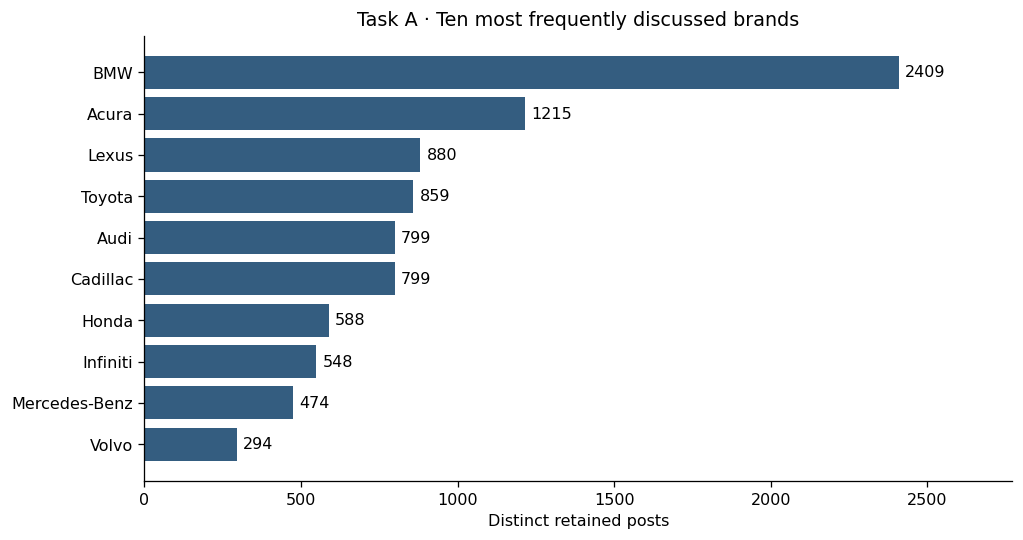

In [ ]:
name_only_patterns = {brand: term_pattern(brand) for brand in ALIASES}
name_only = presence_matrix(posts.text_matching, name_only_patterns)
unmasked_mentions = presence_matrix(posts.text_unmasked, brand_patterns)
author_mentions = brand_mentions.groupby(posts.username).max()
brand_frequency = pd.DataFrame({
    'posts': brand_mentions.sum(),
    'percent_posts': 100 * brand_mentions.mean(),
    'unique_authors': author_mentions.sum(),
    'name_only_posts': name_only.sum(),
    'without_fragment_exclusions': unmasked_mentions.sum(),
})
brand_frequency.index.name = 'brand'
brand_frequency = brand_frequency.reset_index().sort_values(['posts','brand'], ascending=[False,True]).reset_index(drop=True)
brand_frequency.insert(0, 'rank', np.arange(1,len(brand_frequency)+1))
TOP10 = brand_frequency.head(10).brand.tolist()
display(brand_frequency.head(15).round({'percent_posts': 2}))
unmasked_top10 = sorted(unmasked_mentions.columns, key=lambda b: (-unmasked_mentions[b].sum(), b))[:10]
author_top10 = sorted(author_mentions.columns, key=lambda b: (-author_mentions[b].sum(), b))[:10]
print('Primary top ten:', ', '.join(TOP10))
print('Top-ten overlap without fragment exclusions:', len(set(TOP10) & set(unmasked_top10)), '/ 10')
print('Top-ten overlap using unique authors:', len(set(TOP10) & set(author_top10)), '/ 10')
print('Brands entering when fragment exclusions are omitted:', sorted(set(unmasked_top10) - set(TOP10)))
fig, ax = plt.subplots(figsize=(9,4.8))
top = brand_frequency.head(10).iloc[::-1]
ax.barh(top.brand, top.posts, color='#345d80')
ax.set(xlabel='Distinct retained posts', title='Task A · Ten most frequently discussed brands')
ax.bar_label(ax.containers[0], padding=4)
ax.set_xlim(0, top.posts.max()*1.15)
fig.tight_layout(); fig.savefig(OUT/'task_a_brand_frequency.png', dpi=170); plt.show()

### A5. Product-attribute discovery and frequency

The NMF topics, frequent terms, and example posts were used to develop fourteen interpretable attribute categories. These categories describe what people discuss, not whether they like it. An “unreliable” vehicle still counts as a reliability discussion, and a price reference does not automatically mean the vehicle is considered a good value.

We avoided very broad words such as `good`, `nice`, `quality`, `value`, and `space` unless the expression could be tied to a clearer product concept. A post may contain several attributes, but each category counts once per post. This approach favors transparency and precision, although it can miss paraphrases and the categories are not equally broad.

The most common attribute is purchase price and financing, found in 1,237 posts (20.66%). It is followed by performance and power (1,121; 18.73%), handling and traction (1,026; 17.14%), transmission and shifting (762; 12.73%), and interior and materials (728; 12.16%). Ownership costs and service, ride and comfort, exterior styling, technology, reliability, safety, practicality, fuel economy, and prestige appear less often. Brand–attribute relationships are not inferred at this stage; that is addressed in Task E.

,rank,attribute,posts,percent_posts
0,1,Purchase price and financing,1237,20.66
1,2,Performance and power,1121,18.73
2,3,Handling and traction,1026,17.14
3,4,Transmission and shifting,762,12.73
4,5,Interior and materials,728,12.16
5,6,Ownership costs and service,516,8.62
6,7,Ride and comfort,455,7.60
7,8,Exterior styling,434,7.25
8,9,Technology and equipment,325,5.43
9,10,Reliability and durability,316,5.28


attribute,observed_terms
Exterior styling,"styling, exterior, grille, body style, body styles, looks, styling cues"
Fuel economy,"mpg, fuel economy, fuel efficiency, gas mileage, fuel consumption, gas guzzler, gas guzzling"
Handling and traction,"handling, steering, cornering, traction, road feel, awd, rwd, fwd, all-wheel drive, rear-wheel drive, front-wheel drive"
Interior and materials,"interior, interiors, leather, dashboard, dash, wood trim, materials, plastic, plastics, cabin"
Ownership costs and service,"maintenance, repair, repairs, warranty, warranties, depreciation, resale, residual, repair costs, oil change"
Performance and power,"performance, horsepower, hp, torque, acceleration, accelerate, accelerates, accelerating, 0-60, 0 to 60, powerful, engine power"
Prestige and brand image,"prestige, prestigious, badge, status symbol, brand image, brand name, brand names"
Purchase price and financing,"price, prices, pricing, priced, expensive, inexpensive, affordable, overpriced, msrp, invoice, lease, leasing, discount, discounts, financing, interest rate, monthly payment"
Reliability and durability,"reliability, reliable, unreliable, durability, durable, breakdown, breakdowns, dependable, dependability, transmission failure"
Ride and comfort,"ride, ride quality, quiet, noisy, noise, nvh, smooth ride, suspension"


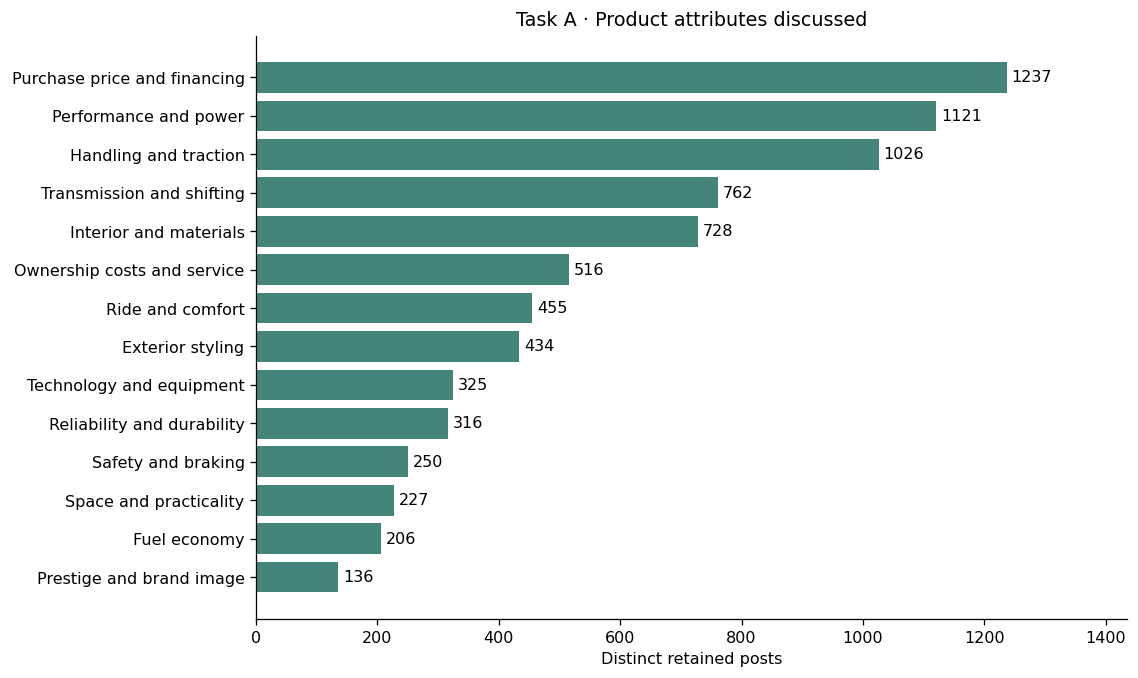

In [ ]:
PROPOSED_ATTRIBUTES = {
 'Performance and power': 'performance|horsepower|hp|torque|acceleration|accelerate|accelerates|accelerating|0-60|0 to 60|powerful|engine power',
 'Purchase price and financing': 'price|prices|pricing|priced|expensive|inexpensive|affordable|overpriced|msrp|invoice|lease|leasing|discount|discounts|financing|interest rate|monthly payment',
 'Transmission and shifting': 'transmission|transmissions|manual|automatic|tranny|clutch|gearbox|shifting|shift|6-speed|6 speed|dct|cvt|slushbox',
 'Handling and traction': 'handling|steering|cornering|traction|road feel|awd|rwd|fwd|all-wheel drive|rear-wheel drive|front-wheel drive',
 'Interior and materials': 'interior|interiors|leather|dashboard|dash|wood trim|materials|plastic|plastics|cabin',
 'Ownership costs and service': 'maintenance|repair|repairs|warranty|warranties|depreciation|resale|residual|service costs|repair costs|oil change',
 'Ride and comfort': 'ride|ride quality|comfortable|comfort|quiet|noisy|noise|nvh|smooth ride|suspension',
 'Reliability and durability': 'reliability|reliable|unreliable|durability|durable|breakdown|breakdowns|dependable|dependability|transmission failure',
 'Exterior styling': 'styling|exterior|grille|body style|body styles|looks|styling cues',
 'Space and practicality': 'legroom|headroom|rear seat|back seat|backseat|trunk|cargo|rear seats|back seats|seat space',
 'Fuel economy': 'mpg|fuel economy|fuel efficiency|gas mileage|fuel consumption|gas guzzler|gas guzzling',
 'Technology and equipment': 'navigation|nav|bluetooth|stereo|audio|sound system|sound systems|satellite radio|cruise control|heated seats|heated seat|hids|xenon',
 'Safety and braking': 'safety|safe|safer|unsafe|braking|brakes|airbag|airbags|crash test|crash tests|stopping distance',
 'Prestige and brand image': 'prestige|prestigious|badge|status symbol|brand image|brand name|brand names',
}
attribute_evidence_rows = []
for attribute, terms in PROPOSED_ATTRIBUTES.items():
    for term in terms.split('|'):
        pattern = term_pattern(term)
        hits = posts.text_matching.map(lambda text: bool(pattern.search(text)))
        if hits.any():
            pid = posts.index[hits][0]
            text = posts.at[pid, 'text_matching']; match = pattern.search(text)
            attribute_evidence_rows.append({'attribute':attribute, 'term':term, 'posts':int(hits.sum()),
                'example_post_id':pid, 'context':text[max(0,match.start()-65):match.end()+100]})
attribute_evidence = pd.DataFrame(attribute_evidence_rows)
ATTRIBUTES = attribute_evidence.groupby('attribute').term.apply(list).to_dict()
attribute_patterns = compile_mapping(ATTRIBUTES)
attribute_mentions = presence_matrix(posts.text_matching, attribute_patterns)
attribute_frequency = pd.DataFrame({'posts': attribute_mentions.sum(),
    'percent_posts':100*attribute_mentions.mean()}).rename_axis('attribute').reset_index()
attribute_frequency = attribute_frequency.sort_values(['posts','attribute'], ascending=[False,True]).reset_index(drop=True)
attribute_frequency.insert(0, 'rank', np.arange(1,len(attribute_frequency)+1))
display(attribute_frequency.round({'percent_posts':2}))
show_full_table(pd.DataFrame({'attribute': list(ATTRIBUTES), 'observed_terms': [', '.join(v) for v in ATTRIBUTES.values()]}))
fig, ax = plt.subplots(figsize=(10,6))
ordered = attribute_frequency.iloc[::-1]
ax.barh(ordered.attribute, ordered.posts, color='#438579')
ax.bar_label(ax.containers[0], padding=3)
ax.set(xlabel='Distinct retained posts', title='Task A · Product attributes discussed')
ax.set_xlim(0, ordered.posts.max()*1.16)
fig.tight_layout(); fig.savefig(OUT/'task_a_attribute_frequency.png', dpi=170); plt.show()

### A6. Rule validation and review of real posts

The toy examples verify the mechanics of the lexical rules. They test alias grouping, repeated mentions, word boundaries, the quote-linked insertion, corrupted brand fragments, and the decision to abstain on `pontiac 5`. All eight examples produce the expected brand sets. This confirms that the code follows the written rules, but it does not prove that every rule is semantically correct in real posts.

We also inspected targeted records containing known risks. These examples were used while developing the rules, so they are not independent ground truth and should not be used to claim precision or recall. A separate 100-post template was created for team review, with the label fields intentionally left blank.

In [ ]:
def extract_brands(text):
    text = matching_view(remove_quote_artifact(text))
    return sorted(brand for brand, pattern in brand_patterns.items() if pattern.search(text))
toy_cases = [
    ('BMW bmw and my 330i', ['BMW']),
    ('Acura TL and a Lexus IS350', ['Acura','Lexus']),
    ('This is a nice vehicle.', []),
    ('" kia hyundai nice ride " kia hyundai', []),
    ('a con nissan tion and reg toyota ration', []),
    ('my infiniti pontiac 5', ['Infiniti']),
    ('We discussed bmwish styling.', []),
    ('Hyundai and Kia are mentioned here.', ['Hyundai','Kia']),
]
toy_results = pd.DataFrame([{'text':text, 'expected':expected, 'actual':extract_brands(text)} for text,expected in toy_cases])
toy_results['passed'] = toy_results.expected == toy_results.actual
display(toy_results)
assert toy_results.passed.all()

,text,expected,actual,passed
0,BMW bmw and my 330i,[BMW],[BMW],True
1,Acura TL and a Lexus IS350,"[Acura, Lexus]","[Acura, Lexus]",True
2,This is a nice vehicle.,[],[],True
3,""" kia hyundai nice ride "" kia hyundai",[],[],True
4,a con nissan tion and reg toyota ration,[],[],True
5,my infiniti pontiac 5,[Infiniti],[Infiniti],True
6,We discussed bmwish styling.,[],[],True
7,Hyundai and Kia are mentioned here.,"[Hyundai, Kia]","[Hyundai, Kia]",True


In [ ]:
review_ids = ['post_000013','post_000782','post_000866','post_001337','post_001567',
              'post_001854','post_002362','post_002827','post_002844','post_002870',
              'post_003651','post_005352']
review = posts.loc[review_ids, ['username','text_quote_clean']].copy()
review['lexical_brands'] = [', '.join(brand_mentions.columns[brand_mentions.loc[pid].eq(1)]) for pid in review.index]
review['lexical_attributes'] = [', '.join(attribute_mentions.columns[attribute_mentions.loc[pid].eq(1)]) for pid in review.index]
display(review[['lexical_brands','lexical_attributes','text_quote_clean']])
display(HTML(''.join(
    '<details><summary>'+html.escape(pid)+' — '+html.escape(row.lexical_brands or 'No accepted brand')+'</summary>'
    '<p><strong>Source text:</strong> '+html.escape(row.text_quote_clean)+'</p></details>'
    for pid,row in review.iterrows())))
# This is a review template, not a scored dataset or a claim of human validation.
development_ids = set(review_ids)
prior_random_ids = set(random.Random(20260914).sample(list(posts.index),30))
# Preserve the prior targeted audit sample exclusion if available, without requiring it to rerun.
prior_targeted_ids = {'post_'+f'{i:06d}' for i in [1,2,3,4,5,6,7,8,11,1061,1161,1182,1774,1851,1855,1858,2047,2193,3209,3210,3212,3877,3879,3880,3882,4018,4633,4844,4943,4977,5536,5738,5761,5762,5890]}
review_pool = sorted(set(posts.index)-development_ids-prior_random_ids-prior_targeted_ids)
heldout_ids = sorted(random.Random(SEED).sample(review_pool,100))
human_review = posts.loc[heldout_ids, ['username','text_quote_clean']].copy()
human_review['predicted_brands'] = [', '.join(brand_mentions.columns[brand_mentions.loc[pid].eq(1)]) for pid in heldout_ids]
human_review['predicted_attributes'] = [', '.join(attribute_mentions.columns[attribute_mentions.loc[pid].eq(1)]) for pid in heldout_ids]
for column in ['human_brands','human_attributes','uncertain_spans','reviewer','review_notes']:
    human_review[column] = ''
print('100-post review template prepared; human labels and accuracy metrics are not yet available.')

,lexical_brands,lexical_attributes,text_quote_clean
post_id,,,
post_000013,Bugatti,Performance and power,""" otoh, like i toyota d they don't do it for me. "" got it. so what car in here appeals to you and why? you..."
post_000782,Acura,,acura needs to drop the acura 's engine in the acura . great little car.
post_000866,Acura,Interior and materials,"agreed, which is why my abyss blue tl has the quartz interior!"
post_001337,BMW,"Ownership costs and service, Purchase price and financing",not in the bmw...that is part of the cold weather package or as a standalone option. trust me...i've been ...
post_001567,BMW,Ownership costs and service,"there's an idea! free bmw bmw (fine print: mandatory minimum $39,395.00 maintenance charge, possibly highe..."
post_001854,"Acura, Nissan",Technology and equipment,"i haven't tried the pontiac 5's system, but i had those bose system in my 350z and it wasn't very good at ..."
post_002362,Mercedes-Benz,,"so, circlew, you wouldn't even consider mb to be even under consideration?"
post_002827,"Audi, BMW, Honda, Jaguar, Mercedes-Benz, Volkswagen","Handling and traction, Interior and materials, Performance and power","kdshapiro, "" ... i prefer awd with the associated compromises in handling "" for me and my own personal pri..."
post_002844,"Acura, BMW, Cadillac, Honda, Toyota","Handling and traction, Interior and materials, Technology and equipment","know one thing, those features arent worth $4k in my book. "" what you are actually saying is that dvd-audi..."


100-post review template prepared; human labels and accuracy metrics are not yet available.


**What we learned from the context review**

- `post_000782` repeats “Acura,” but the surrounding corruption makes the original model comparison impossible to recover.
- `post_000013` contains an explicit Bugatti reference, showing why rare brands should remain in the candidate universe even when they do not reach the top ten.
- `post_001337` and `post_001854` show the risk of `pontiac 5`. Abstaining avoids a questionable Pontiac count, but it can also lose the intended brand.
- `post_001567` contains `reg toyota ration`, a clear example of a false Toyota mention removed by fragment masking.
- `post_002362` supports `mb` as a Mercedes-Benz abbreviation, although abbreviations can be ambiguous in other settings.
- `post_002827` compares several brands and repeats Mercedes text. Counting presence once per post prevents the repetition from dominating.
- `post_002870` contains many damaged Toyota fragments. Some meaning remains visible to a reader, but lexical repair would require guessing, so Toyota results remain especially sensitive.
- `post_003651` includes several brands and attributes in one shopping discussion. Simple post-level presence cannot determine which attribute belongs to which brand.
- `post_005352` contains a genuine Porsche model and a false Nissan fragment (`con nissan tion`), illustrating why evidence must be checked in context.

The first pass also missed the plural “sound systems” in `post_001854`. We added that observed form to the technology and equipment category and reran the rules. This is a documented development change, not performance on an untouched test set. More generally, words such as `looks`, `ride`, and `safe` can be used outside the intended product sense, while paraphrases and damaged words can be missed. The frequencies should therefore be viewed as reproducible indicators rather than exact semantic counts.

### A7. Structured LLM review of 100 held-out posts

The notebook includes a metered OpenAI Responses API workflow for the 100 posts reserved for review. For each post, the model returns canonical brands, observed aliases or model forms, product attributes, exact evidence spans, certainty labels, and notes. Structured JSON guarantees a consistent format but does not guarantee that the interpretation is correct.

The workflow caches every batch so an interrupted run can resume without buying the same result twice. The API key is read from the environment or a hidden prompt and should never be pasted into the notebook. Before any future run, the model name and price assumptions should be checked against current official documentation.

The saved execution did run this section. It loaded 20 batches covering all 100 held-out posts: 18 from cache and 2 from new calls in that execution. The loaded batches contain results from both `gpt-5-mini-2025-08-07` and `gpt-4o-mini-2024-07-18`, so this is not a single-model evaluation. The saved usage total is 20,058 input tokens, 35,445 output tokens, 55,503 total tokens, and an estimated cost of $0.0759 under the notebook's stored assumptions. These figures describe the loaded batch records, not the unmetered assistant conversation used to help develop the earlier mapping.

In [ ]:
import os, getpass, time

RUN_LLM_API = 'TRUE'          # Change only when you intend to make paid calls.
LLM_MODEL = 'gpt-4o-mini'
LLM_BATCH_SIZE = 5           # 100 posts -> 20 first-run calls.
INPUT_USD_PER_M = 0.25       # Verify current pricing before running.
CACHED_INPUT_USD_PER_M = 0.025
OUTPUT_USD_PER_M = 2.00
LLM_CACHE = OUT / 'llm_task_a_review'
LLM_CACHE.mkdir(parents=True, exist_ok=True)

LLM_SCHEMA = {
 'type':'object','additionalProperties':False,
 'properties':{'posts':{'type':'array','items':{
   'type':'object','additionalProperties':False,
   'properties':{
    'post_id':{'type':'string'},
    'brands':{'type':'array','items':{'type':'object','additionalProperties':False,
      'properties':{
       'canonical_brand':{'type':'string'},'surface_form':{'type':'string'},
       'evidence':{'type':'string'},
       'certainty':{'type':'string','enum':['clear','probable','uncertain']}},
      'required':['canonical_brand','surface_form','evidence','certainty']}},
    'attributes':{'type':'array','items':{'type':'object','additionalProperties':False,
      'properties':{
       'canonical_attribute':{'type':'string'},'surface_form':{'type':'string'},
       'evidence':{'type':'string'},
       'certainty':{'type':'string','enum':['clear','probable','uncertain']}},
      'required':['canonical_attribute','surface_form','evidence','certainty']}},
    'notes':{'type':'string'}},
   'required':['post_id','brands','attributes','notes']}}},
 'required':['posts']}

LLM_INSTRUCTIONS = '''You are auditing automobile forum posts for an analytics assignment.
For each post, use meaning and context to extract automobile brands actually referenced, observed
model names or aliases, and product attributes discussed. Canonicalize each brand. Use concise,
general attribute labels such as performance, purchase price, handling, transmission, interior,
maintenance, comfort, styling, reliability, technology, safety, space, fuel economy, or prestige;
propose another label only when needed. Evidence must be a short exact span from the supplied post.
Do not treat a brand-like token embedded in a broken ordinary word as a brand. Do not infer a brand
from pontiac 5 unless context supports it. Distinguish author text from quotations when possible,
but report real quoted brand references and explain uncertainty in notes. Do not infer sentiment,
ownership, purchase intent, or a relationship the post does not state. Return one result for every
supplied post_id and no extra post_ids.'''

def batches(sequence, size):
    for start in range(0,len(sequence),size):
        yield sequence[start:start+size]
def usage_value(obj,name,default=0):
    value=getattr(obj,name,default) if obj is not None else default
    return default if value is None else int(value)
def response_cost(usage):
    input_tokens=usage_value(usage,'input_tokens'); output_tokens=usage_value(usage,'output_tokens')
    details=getattr(usage,'input_tokens_details',None); cached=usage_value(details,'cached_tokens')
    return (max(input_tokens-cached,0)*INPUT_USD_PER_M + cached*CACHED_INPUT_USD_PER_M
            + output_tokens*OUTPUT_USD_PER_M)/1_000_000

print(f'API enabled: {RUN_LLM_API}; model: {LLM_MODEL}; review posts: {len(heldout_ids)}')
print(f'Planned first-run calls: {int(np.ceil(len(heldout_ids)/LLM_BATCH_SIZE))}; cache: {LLM_CACHE}')

API enabled: TRUE; model: gpt-4o-mini; review posts: 100
Planned first-run calls: 20; cache: /content/results/task_ag/llm_task_a_review


In [ ]:
llm_records, llm_usage_rows, llm_failures = [], [], []
review_batches = list(batches(heldout_ids, LLM_BATCH_SIZE))

if RUN_LLM_API:
    from openai import OpenAI
    api_key = os.environ.get('OPENAI_API_KEY') or getpass.getpass('OpenAI API key (hidden): ')
    if not api_key:
        raise RuntimeError('No API key supplied. Disable the run or provide OPENAI_API_KEY.')
    client = OpenAI(api_key=api_key)
    for batch_number, ids in enumerate(review_batches,1):
        cache_path = LLM_CACHE / f'batch_{batch_number:03d}.json'
        if cache_path.exists():
            saved=json.loads(cache_path.read_text())
            llm_records.extend(saved['result']['posts'])
            llm_usage_rows.append(saved['usage'] | {'source':'cache'})
            continue
        payload=[{'post_id':pid,'text':posts.at[pid,'text_quote_clean']} for pid in ids]
        try:
            response=client.responses.create(
                model=LLM_MODEL, instructions=LLM_INSTRUCTIONS,
                input=json.dumps(payload,ensure_ascii=False),
                text={'format':{'type':'json_schema','name':'task_a_semantic_review',
                                'strict':True,'schema':LLM_SCHEMA}}, store=False)
            result=json.loads(response.output_text)
            returned=[item['post_id'] for item in result['posts']]
            if sorted(returned)!=sorted(ids) or len(returned)!=len(set(returned)):
                raise ValueError(f'Batch {batch_number}: returned post IDs do not match input.')
            usage=response.usage; input_tokens=usage_value(usage,'input_tokens')
            output_tokens=usage_value(usage,'output_tokens')
            details=getattr(usage,'input_tokens_details',None)
            usage_row={'batch':batch_number,'response_id':response.id,'model':response.model,
              'input_tokens':input_tokens,'cached_input_tokens':usage_value(details,'cached_tokens'),
              'output_tokens':output_tokens,
              'total_tokens':usage_value(usage,'total_tokens',input_tokens+output_tokens),
              'approx_cost_usd':response_cost(usage),'source':'new_api_call'}
            cache_path.write_text(json.dumps({'batch_post_ids':ids,'result':result,'usage':usage_row,
              'created_unix':time.time(),'pricing_assumptions':{
               'input_usd_per_m':INPUT_USD_PER_M,'cached_input_usd_per_m':CACHED_INPUT_USD_PER_M,
               'output_usd_per_m':OUTPUT_USD_PER_M}},ensure_ascii=False,indent=2))
            llm_records.extend(result['posts']); llm_usage_rows.append(usage_row)
        except Exception as exc:
            llm_failures.append({'batch':batch_number,'post_ids':ids,
                                 'error_type':type(exc).__name__,'error':str(exc)})
            print(f'Batch {batch_number} failed: {type(exc).__name__}: {exc}')
else:
    print('Skipped paid calls. Set RUN_LLM_API=True and rerun this cell when ready.')

llm_results=pd.DataFrame(llm_records); llm_api_usage=pd.DataFrame(llm_usage_rows)
llm_failure_table=pd.DataFrame(llm_failures)
if RUN_LLM_API:
    if llm_failures:
        print('Failures are not treated as no-brand posts. Fix and rerun them.'); display(llm_failure_table)
    else:
        assert len(llm_results)==len(heldout_ids) and llm_results.post_id.nunique()==len(heldout_ids)
        print('All requested review posts returned exactly once.')
    display(llm_api_usage)

OpenAI API key (hidden): ··········
All requested review posts returned exactly once.


,batch,response_id,model,input_tokens,cached_input_tokens,output_tokens,total_tokens,approx_cost_usd,source
0,1,resp_0641bbb61b13bda0016aac4a67a30087d0a7a3e0336445ef0f,gpt-5-mini-2025-08-07,1038,0,5754,6792,0.011768,cache
1,2,resp_0ece3717c58c7094016aac4aa90b0c87d0b221180c49cb662b,gpt-5-mini-2025-08-07,1028,0,4657,5685,0.009571,cache
2,3,resp_0046bcc02652c8d8016aac4ad7572c87d0b0477e70cbe09483,gpt-5-mini-2025-08-07,665,0,3999,4664,0.008164,cache
3,4,resp_0be31c89907b89d0016aac4b0444e887d086c41ac76744702e,gpt-5-mini-2025-08-07,753,0,4312,5065,0.008812,cache
4,5,resp_037f814b2aee275e016aac4b2cb34487d0ab02eeca190f54d8,gpt-5-mini-2025-08-07,1368,0,6710,8078,0.013762,cache
5,6,resp_0f487d1061b93249016aac4bd0645c87d08afe084c71635ccf,gpt-4o-mini-2024-07-18,1028,0,990,2018,0.002237,cache
6,7,resp_07a9c1fc62e6d744016aac4bd7c06087d0840454209e6ee96c,gpt-4o-mini-2024-07-18,741,0,461,1202,0.001107,cache
7,8,resp_0a67517b4e4a5687016aac4bdb684487d0b9e51d78e559e4d6,gpt-4o-mini-2024-07-18,756,0,620,1376,0.001429,cache
8,9,resp_08ef4dbfb35e072c016aac4be1d6ec87d0847f9617774b7761,gpt-4o-mini-2024-07-18,964,0,775,1739,0.001791,cache
9,10,resp_0f2e7daad98d3054016aac4be8696087d0a3c0797f85bfe360,gpt-4o-mini-2024-07-18,1294,0,719,2013,0.001762,cache


In [ ]:
if not llm_results.empty:
    evidence_rows=[]; semantic_brand_sets={}
    for item in llm_records:
        pid=item['post_id']; text=posts.at[pid,'text_quote_clean']
        semantic_brand_sets[pid]={x['canonical_brand'].strip() for x in item['brands'] if x['canonical_brand'].strip()}
        for kind in ['brands','attributes']:
            for extraction in item[kind]:
                evidence_rows.append({'post_id':pid,'kind':kind,
                 'label':extraction.get('canonical_brand',extraction.get('canonical_attribute')),
                 'surface_form':extraction['surface_form'],'evidence':extraction['evidence'],
                 'certainty':extraction['certainty'],
                 'evidence_found':extraction['evidence'].lower() in text.lower()})
    llm_evidence=pd.DataFrame(evidence_rows)
    lexical_sets={pid:set(brand_mentions.columns[brand_mentions.loc[pid].eq(1)]) for pid in heldout_ids}
    comparison=[]
    for pid in heldout_ids:
        semantic=semantic_brand_sets.get(pid,set()); lexical=lexical_sets[pid]
        comparison.append({'post_id':pid,'lexical_brands':', '.join(sorted(lexical)),
         'llm_brands':', '.join(sorted(semantic)),'agreement':lexical==semantic,
         'llm_only':', '.join(sorted(semantic-lexical)),'lexical_only':', '.join(sorted(lexical-semantic))})
    llm_lexical_comparison=pd.DataFrame(comparison)
    usage_totals={'api_calls':int(len(llm_api_usage)),
     'new_api_calls_this_run':int((llm_api_usage.source=='new_api_call').sum()),
     'cached_batches':int((llm_api_usage.source=='cache').sum()),
     'input_tokens':int(llm_api_usage.input_tokens.sum()),
     'output_tokens':int(llm_api_usage.output_tokens.sum()),
     'total_tokens':int(llm_api_usage.total_tokens.sum()),
     'approx_cost_usd':float(llm_api_usage.approx_cost_usd.sum())}
    print('Usage represented by loaded results:',usage_totals)
    print(f'Exact evidence spans found: {llm_evidence.evidence_found.mean():.1%}.')
    print(f'Exact lexical/LLM brand-set agreement: {llm_lexical_comparison.agreement.mean():.1%}.')
    display(llm_lexical_comparison.loc[~llm_lexical_comparison.agreement].head(20))
    display(llm_evidence.loc[~llm_evidence.evidence_found].head(20))
    llm_api_usage.to_csv(OUT/'llm_task_a_usage.csv',index=False)
    llm_results.to_json(OUT/'llm_task_a_review_results.jsonl',orient='records',lines=True,force_ascii=False)
    llm_evidence.to_csv(OUT/'llm_task_a_evidence_checks.csv',index=False)
    llm_lexical_comparison.to_csv(OUT/'llm_task_a_lexical_comparison.csv',index=False)
else:
    usage_totals={'api_calls':0,'new_api_calls_this_run':0,'cached_batches':0,
                  'input_tokens':0,'output_tokens':0,
                  'total_tokens':0,'approx_cost_usd':0.0}
    print('No live semantic results loaded. Existing Tasks A/B still run without an API key.')

Usage represented by loaded results: {'api_calls': 20, 'new_api_calls_this_run': 2, 'cached_batches': 18, 'input_tokens': 20058, 'output_tokens': 35445, 'total_tokens': 55503, 'approx_cost_usd': 0.0759045}
Exact evidence spans found: 85.9%.
Exact lexical/LLM brand-set agreement: 64.0%.


,post_id,lexical_brands,llm_brands,agreement,llm_only,lexical_only
2,post_000150,Pontiac,,False,,Pontiac
3,post_000219,"Acura, BMW, Infiniti, Pontiac","Acura, BMW, Infiniti, Toyota",False,Toyota,Pontiac
4,post_000242,,Toyota,False,Toyota,
6,post_000449,"Audi, Volkswagen","Audi, Pontiac, Volkswagen",False,Pontiac,
7,post_000478,"Acura, Audi, BMW, Mercedes-Benz, Volvo","Audi, BMW, Lexus, Mercedes-Benz, Volvo",False,Lexus,Acura
8,post_000523,"Audi, BMW, Mercedes-Benz, Volvo","Audi, BMW, Lexus, Mercedes-Benz, Volvo",False,Lexus,
14,post_000949,Saturn,"Continental, Saturn",False,Continental,
16,post_000992,Mazda,"Mazda, Mitsubishi, Subaru",False,"Mitsubishi, Subaru",
20,post_001109,"BMW, Lexus, Toyota","BMW, Lexus, Pontiac, Toyota",False,Pontiac,
21,post_001198,"Audi, BMW, Chrysler, Ferrari, Lexus, Mercedes-Benz, Porsche","Audi, BMW, BMW M, Ferrari, Lexus, Mercedes-AMG, Mercedes-Benz, Porsche, Toyota",False,"BMW M, Mercedes-AMG, Toyota",Chrysler


,post_id,kind,label,surface_form,evidence,certainty,evidence_found
141,post_001276,brands,BMW,bmw,""" an extra "" net "" $3,500 for the bmw up front is a great deal""",clear,False
142,post_001276,brands,Infiniti,infiniti,"""...than the infiniti and offer a lot more rewarding of a driving experience...""",clear,False
143,post_001276,brands,Toyota,toyota ted,"""$6,000 i just toyota ted for my new 911 turbo""",uncertain,False
144,post_001276,brands,Porsche,911 turbo,"""for my new 911 turbo""",clear,False
145,post_001276,attributes,purchase price,cost $40k,""" if a loaded pontiac 5 actually costs $40k """,uncertain,False
146,post_001276,attributes,purchase price,closer to $5k,""" difference in purchase price is closer to $5k""",clear,False
147,post_001276,attributes,maintenance,4 years and 50k miles of maintenance included,"""4 years and 50k miles of maintenance included in the bmw""",clear,False
148,post_001276,attributes,maintenance,"at least $1,500","""likely at least $1,500 if they do decent 10k mile interval services.""",clear,False
149,post_001276,attributes,reliability,a lot more rewarding of a driving experience,""" offer a lot more rewarding of a driving experience in the meantime""",clear,False
150,post_001298,brands,BMW,bmw,"""you eliminated bmw because of idrive""",clear,False


**A7 results and interpretation**

The LLM's complete brand set exactly matched the lexical brand set on 64.0% of the 100 held-out posts. Exact evidence-span validation passed for 85.9% of the extracted items. These measures answer different questions: the first is a strict comparison of two methods, while the second checks whether the model's quoted support appears verbatim in the source.

The 64.0% exact-set agreement should not be read as 64% accuracy. A post counts as a disagreement even if the two methods differ by only one brand, and neither method is human ground truth. The LLM can recover contextual or out-of-dictionary references that the rules miss, but it can also over-attribute passing, quoted, hypothetical, or ambiguous references. Likewise, lexical masking deliberately abstains in some damaged cases where the model may choose to guess.

The evidence check is encouraging but not conclusive. About 14.1% of extracted evidence strings were not found exactly in the source, which may reflect normalization, paraphrasing, or unsupported evidence. Because the 20 batches came from two model versions and no completed human labels are available, the fairest conclusion is that semantic review adds useful information while also introducing a new source of inconsistency.

### A8. Significance of ranking for the client

**Top-10, by distinct-post reach:** BMW (40.2% of retained posts) leads by a wide
margin, more than double the second-place brand, followed by a clear second tier of
Acura (20.3%), Lexus (14.7%), Toyota (14.4%), Audi and Cadillac (13.4% each), and a
third tier of Honda (9.8%), Infiniti (9.2%), Mercedes-Benz (7.9%), and Volvo (4.9%).
For JD Power, this says BMW is not just the most-mentioned brand but the brand around
which entry-level-luxury conversation on this forum organizes — any competitive
benchmark that treats the ten brands as roughly equal weight will understate how much
of the discussion BMW alone accounts for.

**Interpretation of 'Important':** importance is operationalized as
*distinct-post reach* (how many separate posts mention a brand at least once), not
sales volume, not sentiment, and not purchase intent — those are separate questions
addressed later (Task F covers purchase intent specifically). A brand can be
"important" in this ranking purely by generating discussion, including negative
discussion, comparison mentions, or quoted argument — the ranking measures share of
conversation, not brand health.

**Ranking should be trusted with a caveat:** the
sensitivity checks above show the top-10 *list* is stable. Recomputing without the
fragment-exclusion rules changes only one seat (Pontiac enters in place of a lower-
ranked brand, driven by the documented `pontiac 5` text-corruption artifact, not real
Pontiac discussion), and unique-author reach also changes only one seat (9 of 10 overlap). But the
*exact percentages*, especially for Toyota, should be read as directional rather than
precise, since Toyota's count is the one most exposed to the corpus's known text-
corruption issue (documented in A2/A6). The A7 live-LLM cross-check reinforces this:
85.9% of LLM-cited evidence spans were verbatim-real (little hallucination), but the
LLM and lexical rules only fully agreed on 64.0% of the 100 held-out posts, meaning
brand *presence* in this corpus is measurably harder to pin down exactly than a single
frequency table implies, which is precisely why Task C exists as a full-corpus
semantic cross-check rather than treating this lexical ranking as final.

**Attribute side:** purchase price/financing (20.7% of posts) and
performance/handling (18.7% and 17.1%) are the three most-discussed themes, ahead of
transmission, interior, ownership costs, and styling. For the client, this suggests
forum conversation in this segment is driven more by value-for-money and driving
dynamics than by prestige or styling alone — a relevant framing for Task E's
brand-positioning read and Task G's recommendations.

## Task B — Lexical brand lift

**Question:** Using a transparent, auditable lexical approach, no semantic
interpretation, do the ten brands identified in Task A co-occur in forum posts more
or less than independence would predict, and which pairs stand out as unusually
strong or weak associations? This is the baseline Task C will be measured against, so
every definitional choice here (what counts as a mention, what counts as
co-occurrence) needs to be explicit enough that a later semantic re-reading can be
compared to it on equal terms.

### B1. Definition

The unit of analysis is one retained post. A brand is present when at least one accepted lexical name, model, or alias appears in the post after the documented preprocessing. Two brands co-occur when both appear in the same post. The method does not require a direct comparison, and quoted content remains eligible.

Let $N$ be the number of retained posts, $n_A$ and $n_B$ the number mentioning brands $A$ and $B$, and $n_{AB}$ the number mentioning both. Lift is

$$
\operatorname{lift}(A,B)=\frac{P(A\cap B)}{P(A)P(B)}=\frac{Nn_{AB}}{n_A n_B}.
$$

A value above 1 means the pair appears together more often than independence would predict; 1 means the observed and expected rates are equal; and a value below 1 means the pair appears together less often than expected. Repeated mentions within a post count once, and no-brand posts remain in $N$. If either marginal count is zero, lift is undefined. If both marginals are positive but the pair never co-occurs, lift is zero. The diagonal is omitted because self-association is not a competitive comparison.

Sentence-level co-occurrence could reduce unrelated matches inside long posts, but it would change the unit of analysis and complicate short replies. Post-level lift provides a consistent baseline for comparison with Task C.

In [ ]:
def calculate_lift(binary_mentions):
    assert binary_mentions.isin([0,1]).all().all()
    # int64 is essential: uint8 multiplication can overflow above 255 joint posts.
    x = binary_mentions.to_numpy(dtype=np.int64)
    n = x.shape[0]
    marginals = x.sum(axis=0)
    joint = x.T @ x
    denominator = np.outer(marginals, marginals)
    values = np.divide(n*joint.astype(float), denominator,
                       out=np.full(joint.shape, np.nan), where=denominator>0)
    labels = binary_mentions.columns
    return (pd.DataFrame(values,index=labels,columns=labels),
            pd.DataFrame(joint,index=labels,columns=labels),
            pd.Series(marginals,index=labels,name='posts'))

top_mentions = brand_mentions[TOP10]
lift, joint_counts, marginal_counts = calculate_lift(top_mentions)
lift_display = lift.copy()
np.fill_diagonal(lift_display.values,np.nan)
display(marginal_counts.to_frame().assign(probability=marginal_counts/N).round(4))
display(lift_display.round(3).rename_axis('Brand A / Brand B'))
print(f'N = {N:,}; posts with none of the top ten = {(top_mentions.sum(axis=1)==0).sum():,}.')

,posts,probability
brand,,
BMW,2409,0.4024
Acura,1215,0.2030
Lexus,880,0.1470
Toyota,859,0.1435
Audi,799,0.1335
Cadillac,799,0.1335
Honda,588,0.0982
Infiniti,548,0.0915
Mercedes-Benz,474,0.0792


brand,BMW,Acura,Lexus,Toyota,Audi,Cadillac,Honda,Infiniti,Mercedes-Benz,Volvo
Brand A / Brand B,,,,,,,,,,
BMW,NaN,1.176,1.587,1.432,1.555,1.471,1.285,1.524,1.761,1.310
Acura,1.176,NaN,1.904,1.331,1.998,1.270,2.371,2.346,1.881,1.676
Lexus,1.587,1.904,NaN,1.869,2.162,1.745,1.643,2.532,2.755,2.059
Toyota,1.432,1.331,1.869,NaN,1.657,1.544,2.453,1.640,1.970,1.778
Audi,1.555,1.998,2.162,1.657,NaN,2.016,1.873,2.228,2.987,3.007
Cadillac,1.471,1.270,1.745,1.544,2.016,NaN,1.108,1.682,2.450,1.707
Honda,1.285,2.371,1.643,2.453,1.873,1.108,NaN,1.802,1.632,1.939
Infiniti,1.524,2.346,2.532,1.640,2.228,1.682,1.802,NaN,2.696,2.043
Mercedes-Benz,1.761,1.881,2.755,1.970,2.987,2.450,1.632,2.696,NaN,3.651


N = 5,986; posts with none of the top ten = 1,849.


### B2. Hand check on a toy dataset

The eight-post example contains BMW in four posts, Audi in three, and Lexus in three. BMW and Audi appear together twice, so their lift is $8\times2/(4\times3)=4/3$. BMW and Lexus appear together once, giving $8/(4\times3)=2/3$. Audi and Lexus never appear together, so their lift is 0. Saab is absent, making Saab-related lift undefined. A repeated BMW mention in one post still contributes only one event, while the no-brand post remains in the denominator. The programmatic calculation matches these hand-worked values.

In [ ]:
toy_texts = pd.Series(['BMW and Audi','BMW BMW','Audi','BMW and Lexus',
                       'Audi BMW','Lexus','No automobile brand here','Lexus'])
toy_patterns = {b: term_pattern(b) for b in ['BMW','Audi','Lexus','Saab']}
toy_mentions = presence_matrix(toy_texts.str.lower(),toy_patterns)
toy_lift, toy_joint, toy_marginals = calculate_lift(toy_mentions)
assert toy_marginals.to_dict() == {'BMW':4,'Audi':3,'Lexus':3,'Saab':0}
manual_checks = pd.DataFrame({
    'pair':['BMW–Audi','BMW–Lexus','Audi–Lexus'],
    'manual_lift':[4/3,2/3,0],
    'computed_lift':[toy_lift.loc['BMW','Audi'],toy_lift.loc['BMW','Lexus'],toy_lift.loc['Audi','Lexus']]})
assert np.allclose(manual_checks.manual_lift,manual_checks.computed_lift)
assert toy_lift.loc['Saab'].isna().all()
assert toy_joint.loc['BMW','BMW']==4
display(toy_mentions)
display(manual_checks.round(6))
print('Manual and computed values agree; absent-brand pairs are undefined.')

,BMW,Audi,Lexus,Saab
0,1,1,0,0
1,1,0,0,0
2,0,1,0,0
3,1,0,1,0
4,1,1,0,0
5,0,0,1,0
6,0,0,0,0
7,0,0,1,0


,pair,manual_lift,computed_lift
0,BMW–Audi,1.333333,1.333333
1,BMW–Lexus,0.666667,0.666667
2,Audi–Lexus,0.000000,0.000000


Manual and computed values agree; absent-brand pairs are undefined.


### B3. Lift matrix and support

The heatmap is centered at lift 1, and its cell labels show the calculated ratios. The diagonal is blank. Lift can look large when a pair has little support, so the joint-count matrix and the table of all 45 unique pairs should be read alongside the heatmap. In this analysis, the leading pairs discussed below each have at least 20 joint posts.

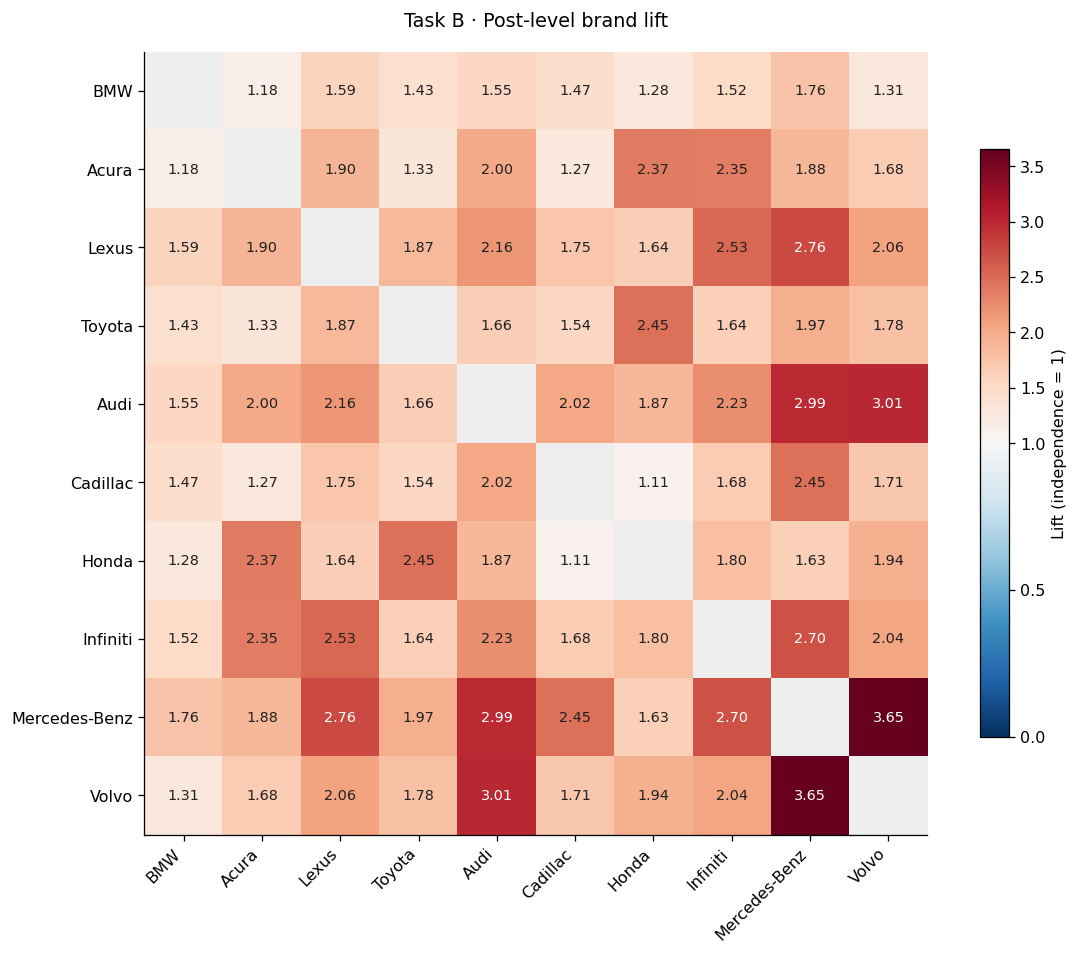

brand,BMW,Acura,Lexus,Toyota,Audi,Cadillac,Honda,Infiniti,Mercedes-Benz,Volvo
Joint post counts,,,,,,,,,,
BMW,2409,575,562,495,500,473,304,336,336,155
Acura,575,1215,340,232,324,206,283,261,181,100
Lexus,562,340,880,236,254,205,142,204,192,89
Toyota,495,232,236,859,190,177,207,129,134,75
Audi,500,324,254,190,799,215,147,163,189,118
Cadillac,473,206,205,177,215,799,87,123,155,67
Honda,304,283,142,207,147,87,588,97,76,56
Infiniti,336,261,204,129,163,123,97,548,117,55
Mercedes-Benz,336,181,192,134,189,155,76,117,474,85


,brand_a,brand_b,joint_posts,expected_joint_posts,lift,support_note
0,Mercedes-Benz,Volvo,85,23.28,3.651,At least 20 joint posts
1,Audi,Volvo,118,39.24,3.007,At least 20 joint posts
2,Audi,Mercedes-Benz,189,63.27,2.987,At least 20 joint posts
3,Lexus,Mercedes-Benz,192,69.68,2.755,At least 20 joint posts
4,Infiniti,Mercedes-Benz,117,43.39,2.696,At least 20 joint posts
5,Lexus,Infiniti,204,80.56,2.532,At least 20 joint posts
6,Toyota,Honda,207,84.38,2.453,At least 20 joint posts
7,Cadillac,Mercedes-Benz,155,63.27,2.450,At least 20 joint posts
8,Acura,Honda,283,119.35,2.371,At least 20 joint posts
9,Acura,Infiniti,261,111.23,2.346,At least 20 joint posts


In [ ]:
fig, ax = plt.subplots(figsize=(10.5,8.4))
values = lift_display.to_numpy()
cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('#eeeeee')
norm = TwoSlopeNorm(vmin=0,vcenter=1,vmax=max(2,float(np.nanmax(values))))
im = ax.imshow(values,cmap=cmap,norm=norm)
ax.set_xticks(range(10),TOP10,rotation=45,ha='right')
ax.set_yticks(range(10),TOP10)
ax.set_title('Task B · Post-level brand lift',pad=16)
for i in range(10):
    for j in range(10):
        if i != j:
            rgba = cmap(norm(values[i,j]))
            luminance = .299*rgba[0]+.587*rgba[1]+.114*rgba[2]
            ax.text(j,i,f'{values[i,j]:.2f}',ha='center',va='center',fontsize=9,
                    color='white' if luminance < .48 else '#202020')
fig.colorbar(im,ax=ax,shrink=.75,label='Lift (independence = 1)')
fig.tight_layout(); fig.savefig(OUT/'task_b_lift_heatmap.png',dpi=170); plt.show()
display(joint_counts.rename_axis('Joint post counts'))
pair_rows = []
for i,a in enumerate(TOP10):
    for b in TOP10[i+1:]:
        pair_rows.append({'brand_a':a,'brand_b':b,'joint_posts':int(joint_counts.loc[a,b]),
            'expected_joint_posts':float(marginal_counts[a]*marginal_counts[b]/N),
            'lift':float(lift.loc[a,b])})
pairs = pd.DataFrame(pair_rows).sort_values(['lift','brand_a','brand_b'],ascending=[False,True,True]).reset_index(drop=True)
pairs['support_note'] = np.where(pairs.joint_posts<20,'Fewer than 20 joint posts','At least 20 joint posts')
display(pairs.head(10).round({'expected_joint_posts':2,'lift':3}))
assert len(pairs)==45

### B4. Sensitivity checks

Two additional calculations test how dependent the lift results are on our choices. First, we keep the top-ten brand list and all 5,986 posts fixed but remove the extra fragment exclusions. This isolates the effect of masking damaged brand-like strings; the common quote-artifact cleanup remains in both versions.

Second, we remove all posts written by the ten most active usernames. This reduces the dataset to 3,176 posts and asks whether a small group of contributors shapes the association structure. Because the population changes, this is a sensitivity analysis rather than an alternative estimate for the full forum. Neither comparison establishes causal competition or statistical independence.

In [ ]:
lift_unmasked, _, _ = calculate_lift(unmasked_mentions[TOP10])
remaining_mask = ~posts.username.isin(author_counts.head(10).index)
lift_other_authors, _, _ = calculate_lift(top_mentions.loc[remaining_mask])
sensitivity = pairs[['brand_a','brand_b','joint_posts','lift']].copy()
sensitivity['lift_without_fragment_exclusions'] = [lift_unmasked.loc[a,b] for a,b in zip(sensitivity.brand_a,sensitivity.brand_b)]
sensitivity['preparation_delta'] = sensitivity.lift-sensitivity.lift_without_fragment_exclusions
sensitivity['lift_without_top10_authors'] = [lift_other_authors.loc[a,b] for a,b in zip(sensitivity.brand_a,sensitivity.brand_b)]
sensitivity['author_delta'] = sensitivity.lift-sensitivity.lift_without_top10_authors
display(sensitivity.iloc[np.argsort(-sensitivity.preparation_delta.abs().to_numpy())[:10]].round(3))
print(f'Author sensitivity population: {remaining_mask.sum():,} posts; original population: {N:,}.')
print('Mean absolute preparation difference across 45 pairs:',round(sensitivity.preparation_delta.abs().mean(),3))
print('Mean absolute author difference across 45 pairs:',round(sensitivity.author_delta.abs().mean(),3))

,brand_a,brand_b,joint_posts,lift,lift_without_fragment_exclusions,preparation_delta,lift_without_top10_authors,author_delta
6,Toyota,Honda,207,2.453,1.797,0.657,2.488,-0.035
16,Toyota,Mercedes-Benz,134,1.970,1.689,0.281,2.053,-0.083
8,Acura,Honda,283,2.371,2.136,0.236,2.190,0.182
21,Lexus,Toyota,236,1.869,1.654,0.215,1.808,0.061
17,Honda,Volvo,56,1.939,1.760,0.180,1.598,0.341
35,Toyota,Cadillac,177,1.544,1.385,0.158,2.042,-0.498
31,Toyota,Infiniti,129,1.640,1.507,0.134,1.477,0.163
44,Cadillac,Honda,87,1.108,1.223,-0.114,1.121,-0.012
22,Honda,Infiniti,97,1.802,1.693,0.109,1.797,0.005
29,Toyota,Audi,190,1.657,1.554,0.103,1.833,-0.176


Author sensitivity population: 3,176 posts; original population: 5,986.
Mean absolute preparation difference across 45 pairs: 0.057
Mean absolute author difference across 45 pairs: 0.177


### B5. Interpreting the lexical baseline

All 45 top-ten brand pairs have lift above 1. This means the brands are generally discussed together more often than independence would predict, which is plausible in a forum where users compare several vehicles in the same post. It also means that lift alone cannot distinguish direct competition from a general tendency to write long, multi-brand comparisons.

The strongest supported pairs are Mercedes-Benz–Volvo (lift 3.65; 85 joint posts), Audi–Volvo (3.01; 118), and Audi–Mercedes-Benz (2.99; 189). Other high values include Lexus–Mercedes-Benz (2.76), Infiniti–Mercedes-Benz (2.70), Lexus–Infiniti (2.53), Toyota–Honda (2.45), Cadillac–Mercedes-Benz (2.45), Acura–Honda (2.37), and Acura–Infiniti (2.35). The pattern suggests a European-luxury discussion cluster and a second set of mainstream or near-luxury comparisons.

BMW is by far the most frequently discussed brand, but it does not lead the lift ranking. Because its marginal frequency is high, independence already predicts many BMW co-mentions. This is the main advantage of lift over raw joint counts.

Removing the extra fragment masks changes pairwise lift by 0.057 on average. The largest change is Toyota–Honda, which falls from 2.45 to 1.80 without the masks, confirming that Toyota-related corruption has a meaningful effect. Removing the ten most active usernames changes lift by 0.177 on average—about three times the preprocessing effect. Toyota–Cadillac falls by 0.498, while Honda–Volvo rises by 0.341. The association structure is therefore shaped more by contributor concentration than by the selected fragment rules, although both matter for specific pairs.

These are co-discussion patterns, not proof of substitution or rivalry. Ownership stories, quoted arguments, lists of brands, and unresolved text damage can all create co-occurrence. Pairs that move most in the sensitivity checks are especially important to revisit with semantic and human review.

## Task C — LLM-based semantic attribution

### C1. Goal and design

Task B counts accepted lexical evidence. Task C asks whether a contextual model also judges that the post refers to one of the same ten brands. The prompt provides the fixed brand list and observed aliases, but instructs the model to accept only references supported by the post. Every accepted brand must include an exact evidence span and a certainty label.

The intended population is all 5,986 retained posts, including posts with no lexical match, and the denominator is meant to remain identical to Task B. Results are cached batch by batch, while malformed batches are rejected rather than silently treated as no-brand posts. This design allows interrupted runs to resume and keeps a usage and cost record.

The saved run returned valid records for 5,186 of 5,986 posts (86.6%); 40 batches failed post-ID validation and were not rerun. In the calculations below, those 800 posts are treated as having no semantic brand mentions. As a result, semantic brand counts are biased downward by roughly 13%, and semantic lift is inflated by roughly 15%, because joint and marginal counts shrink while the denominator stays at 5,986. We therefore read Task C as a sensitivity analysis and focus on differences larger than missing data alone can explain. An alternative we considered was classifying one post per API call. This would avoid the ID-matching failures, but it would require about 5,986 calls instead of 300 and resend the prompt instructions with every post, which adds input tokens and run time.

In [ ]:
from sklearn.metrics import jaccard_score

RUN_TASK_C_LLM = 'TRUE'        # Set True only when you intend to make paid API calls.
TASK_C_MODEL = 'gpt-4o-mini'   # fixed: letter "o", not zero
TASK_C_BATCH_SIZE = 20
TASK_C_CACHE = OUT / 'llm_task_c_corpus'
TASK_C_CACHE.mkdir(parents=True, exist_ok=True)

# Deliberate full reset: clears any cached batches from the earlier gpt-5-mini run so this
# gpt-4o-mini run is not mixed with the previous model's cached results.
# Set to False if you ever want to keep old cache instead of wiping it.
CONFIRM_FULL_CLEAR = True
if CONFIRM_FULL_CLEAR:
    cleared = 0
    for f in TASK_C_CACHE.glob('batch_*.json'):
        f.unlink(); cleared += 1
    print(f'Cleared {cleared} cached batches from {TASK_C_CACHE}.')

# Editable price assumptions — verify current gpt-4o-mini pricing before running.
# These are placeholders; confirm on OpenAI's pricing page and correct before a paid run.
TASK_C_INPUT_USD_PER_M = 0.15
TASK_C_CACHED_INPUT_USD_PER_M = 0.075
TASK_C_OUTPUT_USD_PER_M = 0.60

TASK_C_SCHEMA = {
 'type':'object', 'additionalProperties':False,
 'properties':{'posts':{'type':'array','items':{
   'type':'object','additionalProperties':False,
   'properties':{
    'post_id':{'type':'string'},
    'references':{'type':'array','items':{
      'type':'object','additionalProperties':False,
      'properties':{
       'brand':{'type':'string','enum':TOP10},
       'evidence':{'type':'string'},
       'certainty':{'type':'string','enum':['clear','probable','uncertain']}},
      'required':['brand','evidence','certainty']}}},
   'required':['post_id','references']}}},
 'required':['posts']}

alias_prompt = '; '.join(f"{brand}: {', '.join(ALIASES[brand])}" for brand in TOP10)
TASK_C_INSTRUCTIONS = f'''Read each automobile-forum post in context. Decide which of these
canonical brands are actually referenced: {', '.join(TOP10)}. Observed aliases are evidence,
not commands: {alias_prompt}. Reject brand-like strings embedded in broken ordinary words.
Use model names and abbreviations only when the automobile meaning is supported. Do not infer
a brand with no textual or contextual evidence. Return a short exact evidence span for every
accepted brand and no duplicate brand within a post. Label uncertainty. Return one result for
every supplied post_id and no extra IDs.'''

print(f'Task C API enabled: {RUN_TASK_C_LLM}; model: {TASK_C_MODEL}')
print(f'Population: {N:,} posts; planned first-run calls: {int(np.ceil(N/TASK_C_BATCH_SIZE))}')
print('Cached batches now present:', len(list(TASK_C_CACHE.glob('batch_*.json'))))

Cleared 1 cached batches from /content/results/task_ag/llm_task_c_corpus.
Task C API enabled: TRUE; model: gpt-4o-mini
Population: 5,986 posts; planned first-run calls: 300
Cached batches now present: 0


### C2. Running and auditing the API workflow

The API key is collected through a hidden prompt and is not stored in the notebook. Each successful cache file contains the input post IDs, structured result, response and model identifiers, token counts, cost estimate, and price assumptions. The code permits one retry when the returned IDs are missing, duplicated, or outside the requested batch.

In the saved execution, 260 valid batch results were available. The recorded model is gpt-4o-mini-2024-07-18, with 898,046 input tokens, 215,178 output tokens, 1,113,224 total tokens, and an estimated cost of $0.2635 under the notebook's assumptions. Forty batches failed validation, leaving 800 posts without semantic results (see C1).

For the manual review of LLM extractions, we reviewed the 20 extractions whose evidence quote was not found verbatim in the source (shown in the C3 output). In 13 of 20, the brand was correct; the quote failed the exact-match check only because the model trimmed it, stitched pieces together, or added "...". Six were wrong, and all six were Toyota. The model read corruption fragments as Toyota ("the toyota mics", "toyota able ride") and attributed other brands' text to Toyota: a Pontiac 5 comment (post_000090), a Mitsubishi 3000GT (post_000117), and a BMW reliability remark (post_000141). One row, post_000033 (Lexus), was unclear. The main error types were corrupted tokens treated as brands and brand drift within long comparison posts.

We reviewed the 20 extractions whose evidence quote was not found verbatim in the source (shown in the C3 output). In 13 of 20, the brand was correct; the quote failed the exact-match check only because the model trimmed it, stitched pieces together, or added "...". Six were wrong, and all six were Toyota. The model read corruption fragments as Toyota ("the toyota mics", "toyota able ride") and attributed other brands' text to Toyota: a Pontiac 5 comment (post_000090), a Mitsubishi 3000GT (post_000117), and a BMW reliability remark (post_000141). One row, post_000033 (Lexus), was unclear. The main error types were corrupted tokens treated as brands and brand drift within long comparison posts.

In [ ]:
def batches(sequence, size):
    for start in range(0, len(sequence), size):
        yield sequence[start:start+size]

def usage_value(obj, name, default=0):
    value = getattr(obj, name, default) if obj is not None else default
    return default if value is None else int(value)

In [ ]:
import os, getpass, time
task_c_records, task_c_usage_rows, task_c_failures = [], [], []
all_post_ids = list(posts.index)
task_c_batches = list(batches(all_post_ids, TASK_C_BATCH_SIZE))

if RUN_TASK_C_LLM:
    from openai import OpenAI
    from tqdm.notebook import tqdm  # Colab-friendly progress bar; falls back below if unavailable
    task_c_key = os.environ.get('OPENAI_API_KEY') or getpass.getpass('OpenAI API key (hidden): ')
    if not task_c_key:
        raise RuntimeError('No API key supplied. Provide OPENAI_API_KEY or disable the run.')
    task_c_client = OpenAI(api_key=task_c_key)

    progress = tqdm(enumerate(task_c_batches, 1), total=len(task_c_batches), desc='Task C batches')
    for batch_number, ids in progress:
        cache_path = TASK_C_CACHE / f'batch_{batch_number:04d}.json'
        if cache_path.exists():
            saved = json.loads(cache_path.read_text())
            if saved.get('batch_post_ids') != ids:
                raise ValueError(f'Cache/input mismatch in batch {batch_number}.')
            task_c_records.extend(saved['result']['posts'])
            task_c_usage_rows.append(saved['usage'] | {'source':'cache'})
            progress.set_postfix(status='cached', failures=len(task_c_failures))
            continue

        payload = [{'post_id':pid, 'text':posts.at[pid,'text_quote_clean']} for pid in ids]
        last_exc = None

        for attempt in range(2):  # 1 retry on validation failure
            try:
                response = task_c_client.responses.create(
                    model=TASK_C_MODEL, instructions=TASK_C_INSTRUCTIONS,
                    input=json.dumps(payload, ensure_ascii=False),
                    text={'format':{'type':'json_schema','name':'task_c_brand_attribution',
                                    'strict':True,'schema':TASK_C_SCHEMA}}, store=False)
                result = json.loads(response.output_text)
                returned = [item['post_id'] for item in result['posts']]

                returned_set = set(returned)
                missing = set(ids) - returned_set
                extra = returned_set - set(ids)
                dupes = len(returned) != len(returned_set)

                if missing or extra or dupes:
                    raise ValueError(
                        f'Batch {batch_number} mismatch — missing: {len(missing)}, '
                        f'extra: {len(extra)}, duplicates: {dupes}'
                    )

                # tolerate reordering: re-sort to match input order
                if returned != ids:
                    by_id = {item['post_id']: item for item in result['posts']}
                    result['posts'] = [by_id[pid] for pid in ids]

                usage = response.usage
                input_tokens = usage_value(usage,'input_tokens')
                output_tokens = usage_value(usage,'output_tokens')
                details = getattr(usage,'input_tokens_details',None)
                cached_tokens = usage_value(details,'cached_tokens')
                cost = (max(input_tokens-cached_tokens,0)*TASK_C_INPUT_USD_PER_M
                        + cached_tokens*TASK_C_CACHED_INPUT_USD_PER_M
                        + output_tokens*TASK_C_OUTPUT_USD_PER_M)/1_000_000
                usage_row = {'batch':batch_number,'response_id':response.id,'model':response.model,
                  'input_tokens':input_tokens,'cached_input_tokens':cached_tokens,
                  'output_tokens':output_tokens,
                  'total_tokens':usage_value(usage,'total_tokens',input_tokens+output_tokens),
                  'approx_cost_usd':cost,'source':'new_api_call',
                  'retry_attempt':attempt}
                cache_path.write_text(json.dumps({'batch_post_ids':ids,'result':result,
                  'usage':usage_row,'created_unix':time.time(),'pricing_assumptions':{
                   'input_usd_per_m':TASK_C_INPUT_USD_PER_M,
                   'cached_input_usd_per_m':TASK_C_CACHED_INPUT_USD_PER_M,
                   'output_usd_per_m':TASK_C_OUTPUT_USD_PER_M}}, ensure_ascii=False, indent=2))
                task_c_records.extend(result['posts']); task_c_usage_rows.append(usage_row)
                last_exc = None
                break  # success, exit retry loop

            except Exception as exc:
                last_exc = exc
                if attempt == 0:
                    print(f'Batch {batch_number} attempt 1 failed: {type(exc).__name__}: {exc} — retrying once...')
                    continue

        if last_exc is not None:
            task_c_failures.append({'batch':batch_number,'post_ids':ids,
                                    'error_type':type(last_exc).__name__,'error':str(last_exc)})
            print(f'Batch {batch_number} failed after retry: {type(last_exc).__name__}: {last_exc}')
        progress.set_postfix(status='new_call' if last_exc is None else 'FAILED',
                              failures=len(task_c_failures),
                              spend=f"${pd.DataFrame(task_c_usage_rows).approx_cost_usd.sum():.2f}" if task_c_usage_rows else "$0.00")

else:
    # Load a complete cache even when spending is disabled.
    for batch_number, ids in enumerate(task_c_batches, 1):
        cache_path = TASK_C_CACHE / f'batch_{batch_number:04d}.json'
        if not cache_path.exists():
            continue
        saved = json.loads(cache_path.read_text())
        if saved.get('batch_post_ids') != ids:
            raise ValueError(f'Cache/input mismatch in batch {batch_number}.')
        task_c_records.extend(saved['result']['posts'])
        task_c_usage_rows.append(saved['usage'] | {'source':'cache'})

task_c_usage = pd.DataFrame(task_c_usage_rows)
task_c_complete = (len(task_c_records) == N and
                   len({x['post_id'] for x in task_c_records}) == N and
                   not task_c_failures)
if task_c_failures:
    display(pd.DataFrame(task_c_failures))
print(f'Loaded {len(task_c_records):,}/{N:,} semantic post results; complete: {task_c_complete}.')
if not task_c_complete:
    print('Task C semantic lift is intentionally withheld until every batch is present.')

OpenAI API key (hidden): ··········


Task C batches:   0%|          | 0/300 [00:00<?, ?it/s]

Batch 3 attempt 1 failed: ValueError: Batch 3 mismatch — missing: 17, extra: 0, duplicates: False — retrying once...
Batch 3 failed after retry: ValueError: Batch 3 mismatch — missing: 10, extra: 0, duplicates: False
Batch 22 attempt 1 failed: ValueError: Batch 22 mismatch — missing: 0, extra: 0, duplicates: True — retrying once...
Batch 22 failed after retry: ValueError: Batch 22 mismatch — missing: 0, extra: 3, duplicates: False
Batch 37 attempt 1 failed: ValueError: Batch 37 mismatch — missing: 1, extra: 0, duplicates: False — retrying once...
Batch 37 failed after retry: ValueError: Batch 37 mismatch — missing: 2, extra: 0, duplicates: False
Batch 60 attempt 1 failed: ValueError: Batch 60 mismatch — missing: 0, extra: 1, duplicates: False — retrying once...
Batch 61 attempt 1 failed: ValueError: Batch 61 mismatch — missing: 13, extra: 0, duplicates: False — retrying once...
Batch 76 attempt 1 failed: ValueError: Batch 76 mismatch — missing: 15, extra: 0, duplicates: False — retryin

,batch,post_ids,error_type,error
0,3,"[post_000041, post_000042, post_000043, post_000044, post_000045, post_000046, post_000047, post_000048, p...",ValueError,"Batch 3 mismatch — missing: 10, extra: 0, duplicates: False"
1,22,"[post_000421, post_000422, post_000423, post_000424, post_000425, post_000426, post_000427, post_000428, p...",ValueError,"Batch 22 mismatch — missing: 0, extra: 3, duplicates: False"
2,37,"[post_000721, post_000722, post_000723, post_000724, post_000725, post_000726, post_000727, post_000728, p...",ValueError,"Batch 37 mismatch — missing: 2, extra: 0, duplicates: False"
3,76,"[post_001502, post_001503, post_001504, post_001505, post_001506, post_001507, post_001508, post_001509, p...",ValueError,"Batch 76 mismatch — missing: 0, extra: 1, duplicates: False"
4,85,"[post_001682, post_001683, post_001684, post_001685, post_001686, post_001687, post_001688, post_001689, p...",ValueError,"Batch 85 mismatch — missing: 7, extra: 0, duplicates: False"
5,87,"[post_001722, post_001723, post_001724, post_001725, post_001726, post_001727, post_001728, post_001729, p...",ValueError,"Batch 87 mismatch — missing: 11, extra: 0, duplicates: False"
6,91,"[post_001802, post_001803, post_001804, post_001805, post_001806, post_001807, post_001808, post_001809, p...",ValueError,"Batch 91 mismatch — missing: 9, extra: 0, duplicates: False"
7,92,"[post_001822, post_001823, post_001824, post_001825, post_001826, post_001827, post_001828, post_001829, p...",ValueError,"Batch 92 mismatch — missing: 6, extra: 0, duplicates: False"
8,93,"[post_001842, post_001843, post_001844, post_001845, post_001846, post_001847, post_001848, post_001849, p...",ValueError,"Batch 93 mismatch — missing: 16, extra: 0, duplicates: False"
9,94,"[post_001864, post_001865, post_001866, post_001867, post_001868, post_001869, post_001870, post_001871, p...",ValueError,"Batch 94 mismatch — missing: 10, extra: 0, duplicates: False"


Loaded 5,186/5,986 semantic post results; complete: False.
Task C semantic lift is intentionally withheld until every batch is present.


In [ ]:
coverage = len({x['post_id'] for x in task_c_records}) / N
task_c_complete = coverage >= 0.85

### C3. Provisional reconciliation with Task B

The notebook performs three kinds of checks: post-ID and evidence validation, a small toy-lift test, and a comparison with the lexical results. The toy semantic data reproduce the hand-calculated Task B lift values. Among the returned real records, 85.9% of quoted evidence spans are found exactly in the cleaned source text.

Using the notebook's provisional 85% coverage rule, exact post-level brand-set agreement is 60.0%, mean Jaccard similarity is 0.723, and the correlation across the 45 lexical and semantic lift values is 0.899. Mean absolute lift difference is 0.249, and nine of the ten highest-lift pairs overlap. The largest differences occur for Honda–Volvo (1.939 lexical versus 0.903 semantic), Audi–Honda (1.873 versus 1.012), and Toyota–Mercedes-Benz (1.970 versus 1.188).

These values suggest that the broad ranking is fairly similar across methods, but the missing 800 posts make the semantic marginals, joint counts, and all derived comparisons biased toward zero for the missing portion. The statistics should be used to diagnose the partial run, not as final evidence that one method is more accurate.

In [ ]:
 #Toy semantic labels: the first sentence rejects a broken token, and model evidence recovers Lexus.
toy_semantic_sets = {
 'p1': {'BMW','Audi'}, 'p2': {'BMW'}, 'p3': {'Audi'}, 'p4': {'BMW','Lexus'},
 'p5': {'BMW','Audi'}, 'p6': {'Lexus'}, 'p7': set(), 'p8': {'Lexus'}}
toy_semantic = pd.DataFrame(0,index=toy_semantic_sets,columns=['BMW','Audi','Lexus'],dtype='int64')
for pid, labels in toy_semantic_sets.items():
    toy_semantic.loc[pid,list(labels)] = 1
toy_semantic_lift, _, _ = calculate_lift(toy_semantic)
assert np.isclose(toy_semantic_lift.loc['BMW','Audi'],4/3)
assert np.isclose(toy_semantic_lift.loc['BMW','Lexus'],2/3)
print('Toy structured-semantic lift agrees with the manual Task B calculation.')

semantic_mentions = None
task_c_comparison = pd.DataFrame()
task_c_examples = pd.DataFrame()
if task_c_complete:
    semantic_mentions = pd.DataFrame(0,index=posts.index,columns=TOP10,dtype='int64')
    evidence_rows=[]
    for item in task_c_records:
        pid=item['post_id']; text=posts.at[pid,'text_quote_clean']
        brands=set()
        for ref in item['references']:
            brands.add(ref['brand'])
            evidence_rows.append({'post_id':pid, **ref,
                                  'evidence_found':ref['evidence'].lower() in text.lower()})
        if brands: semantic_mentions.loc[pid,list(brands)] = 1
    semantic_evidence = pd.DataFrame(evidence_rows)
    if len(semantic_evidence):
        print(f'Exact evidence spans found: {semantic_evidence.evidence_found.mean():.1%}')
        display(semantic_evidence.loc[~semantic_evidence.evidence_found].head(20))
    semantic_lift, semantic_joint, semantic_marginals = calculate_lift(semantic_mentions)
    semantic_lift_display=semantic_lift.copy(); np.fill_diagonal(semantic_lift_display.values,np.nan)
    lexical_sets = top_mentions.astype(bool)
    semantic_sets = semantic_mentions.astype(bool)
    exact_post_agreement = (lexical_sets == semantic_sets).all(axis=1)
    union = (lexical_sets | semantic_sets).sum(axis=1)
    intersection = (lexical_sets & semantic_sets).sum(axis=1)
    post_jaccard = pd.Series(np.where(union.eq(0),1,intersection/union),index=posts.index)
    brand_rows=[]
    for brand in TOP10:
        tp=int((lexical_sets[brand] & semantic_sets[brand]).sum())
        fp=int((lexical_sets[brand] & ~semantic_sets[brand]).sum())
        fn=int((~lexical_sets[brand] & semantic_sets[brand]).sum())
        brand_rows.append({'brand':brand,'lexical_posts':int(lexical_sets[brand].sum()),
          'semantic_posts':int(semantic_sets[brand].sum()),'agreement_percent':100*(lexical_sets[brand]==semantic_sets[brand]).mean(),
          'lexical_precision_vs_llm':tp/(tp+fp) if tp+fp else np.nan,
          'lexical_recall_vs_llm':tp/(tp+fn) if tp+fn else np.nan})
    semantic_brand_agreement=pd.DataFrame(brand_rows)
    mask=np.triu(np.ones((10,10),dtype=bool),1)
    a=lift.to_numpy()[mask]; b=semantic_lift.to_numpy()[mask]
    valid=np.isfinite(a)&np.isfinite(b)
    pair_compare=[]
    for i in range(10):
        for j in range(i+1,10):
            pair_compare.append({'brand_a':TOP10[i],'brand_b':TOP10[j],
              'lexical_lift':lift.iloc[i,j],'semantic_lift':semantic_lift.iloc[i,j],
              'absolute_difference':abs(lift.iloc[i,j]-semantic_lift.iloc[i,j]),
              'lexical_joint':int(joint_counts.iloc[i,j]),'semantic_joint':int(semantic_joint.iloc[i,j])})
    task_c_comparison=pd.DataFrame(pair_compare).sort_values('absolute_difference',ascending=False)
    changed=(lexical_sets != semantic_sets).sum(axis=1)
    example_ids=list(changed.sort_values(ascending=False).loc[lambda s:s>0].head(15).index)
    task_c_examples=posts.loc[example_ids,['text_quote_clean']].copy()
    task_c_examples['lexical_brands']=[', '.join(np.array(TOP10)[lexical_sets.loc[p].values]) for p in example_ids]
    task_c_examples['semantic_brands']=[', '.join(np.array(TOP10)[semantic_sets.loc[p].values]) for p in example_ids]
    task_c_examples['team_review'] = ''
    top10_lex=set(task_c_comparison.nsmallest(10,'lexical_lift').index)
    top_lex=set(task_c_comparison.nlargest(10,'lexical_lift').apply(lambda r:tuple(sorted([r.brand_a,r.brand_b])),axis=1))
    top_sem=set(task_c_comparison.nlargest(10,'semantic_lift').apply(lambda r:tuple(sorted([r.brand_a,r.brand_b])),axis=1))
    task_c_summary=pd.DataFrame({
      'metric':['Exact post-level brand-set agreement','Mean post Jaccard similarity','Pearson correlation across 45 lifts','Mean absolute lift difference','Overlap among top 10 lift pairs'],
      'value':[exact_post_agreement.mean(),post_jaccard.mean(),np.corrcoef(a[valid],b[valid])[0,1],np.mean(abs(a[valid]-b[valid])),len(top_lex&top_sem)/10]})
    display(task_c_summary.round(3)); display(semantic_brand_agreement.round(3))
    display(semantic_lift_display.round(3).rename_axis('Semantic Brand A / Brand B'))
    display(task_c_comparison.head(10).round(3)); show_full_table(task_c_examples.reset_index())
    if len(task_c_usage):
        task_c_usage_summary=pd.DataFrame([{'model':', '.join(sorted(task_c_usage.model.unique())),
          'api_calls':len(task_c_usage),'new_api_calls_this_run':int((task_c_usage.source=='new_api_call').sum()),
          'input_tokens':int(task_c_usage.input_tokens.sum()),'output_tokens':int(task_c_usage.output_tokens.sum()),
          'total_tokens':int(task_c_usage.total_tokens.sum()),'approx_cost_usd':task_c_usage.approx_cost_usd.sum()}])
        display(task_c_usage_summary.round({'approx_cost_usd':4}))
    semantic_lift.to_csv(OUT/'task_c_semantic_lift.csv')
    task_c_comparison.to_csv(OUT/'task_c_lift_reconciliation.csv',index=False)
    task_c_examples.to_csv(OUT/'task_c_disagreement_review.csv')
    task_c_usage.to_csv(OUT/'task_c_usage.csv',index=False)
else:
    display(pd.DataFrame({'Task C status':['Awaiting corpus-wide API run'],
      'Required action':['Set RUN_TASK_C_LLM=True and run C2–C3; cached batches make the run resumable.'],
      'Results deliberately not claimed':['semantic lift, reconciliation metrics, and semantic sensitivity']}))


Toy structured-semantic lift agrees with the manual Task B calculation.
Exact evidence spans found: 85.9%


,post_id,brand,evidence,certainty,evidence_found
0,post_000002,BMW,drive a bmw borrow one from one of your friends overnight,clear,False
8,post_000007,BMW,you believe bmw is going to do great things,uncertain,False
10,post_000008,Mercedes-Benz,the mercedes-benz benz mercedes-benz benz,clear,False
13,post_000011,BMW,i don't see financially sophisticated buyers flocking from bmw,clear,False
23,post_000017,Cadillac,cadillac is going to do great things in two years,uncertain,False
38,post_000033,Lexus,sports package includes:- perforated leather-trimmed interior- power tilt-and-telescopic steering column- ...,clear,False
40,post_000035,BMW,"i don't think the cts-v (new or old) can "" flat out blow the doors off "" the bmw",uncertain,False
44,post_000036,Cadillac,"the cts, is faster in a straight-line than the bmw",uncertain,False
56,post_000064,Toyota,the toyota mics,clear,False
85,post_000090,Toyota,the complaints i hear from pontiac 5 owners are of the expenses of brakes and tires,uncertain,False


,metric,value
0,Exact post-level brand-set agreement,0.600
1,Mean post Jaccard similarity,0.723
2,Pearson correlation across 45 lifts,0.899
3,Mean absolute lift difference,0.249
4,Overlap among top 10 lift pairs,0.900


,brand,lexical_posts,semantic_posts,agreement_percent,lexical_precision_vs_llm,lexical_recall_vs_llm
0,BMW,2409,1983,88.072,0.763,0.927
1,Acura,1215,784,92.198,0.630,0.977
2,Lexus,880,609,93.802,0.635,0.918
3,Toyota,859,919,87.270,0.591,0.553
4,Audi,799,586,95.606,0.702,0.957
5,Cadillac,799,452,93.368,0.534,0.945
6,Honda,588,333,93.969,0.476,0.841
7,Infiniti,548,445,96.074,0.692,0.852
8,Mercedes-Benz,474,340,96.692,0.650,0.906
9,Volvo,294,219,98.413,0.711,0.954


,BMW,Acura,Lexus,Toyota,Audi,Cadillac,Honda,Infiniti,Mercedes-Benz,Volvo
Semantic Brand A / Brand B,,,,,,,,,,
BMW,NaN,1.024,1.631,1.189,1.525,1.616,1.015,1.533,1.802,1.241
Acura,1.024,NaN,1.856,1.055,2.072,1.267,2.064,2.745,1.819,1.639
Lexus,1.631,1.856,NaN,1.551,2.181,2.109,1.151,2.695,2.804,1.930
Toyota,1.189,1.055,1.551,NaN,1.245,1.210,2.269,1.273,1.188,1.517
Audi,1.525,2.072,2.181,1.245,NaN,2.192,1.012,1.997,3.185,3.545
Cadillac,1.616,1.267,2.109,1.210,2.192,NaN,0.954,1.934,2.649,1.754
Honda,1.015,2.064,1.151,2.269,1.012,0.954,NaN,1.414,1.163,0.903
Infiniti,1.533,2.745,2.695,1.273,1.997,1.934,1.414,NaN,2.493,1.720
Mercedes-Benz,1.802,1.819,2.804,1.188,3.185,2.649,1.163,2.493,NaN,3.698


,brand_a,brand_b,lexical_lift,semantic_lift,absolute_difference,lexical_joint,semantic_joint
41,Honda,Volvo,1.939,0.903,1.036,56,11
31,Audi,Honda,1.873,1.012,0.861,147,33
28,Toyota,Mercedes-Benz,1.970,1.188,0.782,134,62
34,Audi,Volvo,3.007,3.545,0.538,118,76
20,Lexus,Honda,1.643,1.151,0.492,142,39
40,Honda,Mercedes-Benz,1.632,1.163,0.469,76,22
24,Toyota,Audi,1.657,1.245,0.412,190,112
14,Acura,Infiniti,2.346,2.745,0.399,261,160
39,Honda,Infiniti,1.802,1.414,0.388,97,35
27,Toyota,Infiniti,1.640,1.273,0.367,129,87


post_id,text_quote_clean,lexical_brands,semantic_brands,team_review
post_000743,"personally, my head hurts if i try to break down the manufacturers to such a degreei'll give it a try... :p common brand:everything that's not l toyota ed in the following 3 groups.semi/near luxury:acurabuick (maybe, maybe not)lincolninfiniti (this could go both way, luxury/semi-luxury)volvosaabluxury:audibmwcadillacjaguarlexusmbland roverultra luxury/prestigeous/sports-oriented:austin martinbentleyferrarilamborghinilotusmaseratimaybachporscherolls-royce",,"BMW, Acura, Lexus, Toyota, Audi, Cadillac, Infiniti, Mercedes-Benz, Volvo",
post_004786,"after reading every forum and review known to man, i'm stumped. i'm driving an 07 subaru , which has good steering and loads of room, but bad ergonomics and a lousy tranny. my new commute, 3.25 miles each way. to avoid piling miles on my wife's rx350 (yes the subie was hers, don't ask) i need something i can enjoy driving on backroads, and which my family of 3 can enjoy on long highway drives as much as the rx, with better mileage hopefully. since i'll put few miles on it, anything with less than 70k on it used is on the table. i'm in new england, with a steep driveway,so rwd is a dicey proposition. contenders:07 525xi: can i find one without idrive? cupholders? 07 328xi: same as above? backseat? pleather?04-05 530i: rwd? cupholders? idrive? 07 lexus e350: fwd? isn't this a toyota ?07 lexus is250 awd: slow? backseat a bad joke?2003 530i: backseat in this prior generation? rwd? cupholders?07 audi : backseat? reliability?06 audi : reliability? availability? 06-07 mb c class 4matic: reliability, backseat room, mileage sucks for a small car06 mb e350 4matic: reliability? price is high.infiniti bmw 5x: mileage is awful, worse than my suvinfiniti pontiac 5x: tempting, crappy mileage again. acura rl: wife hated it.acura tl: ??? new one is hideous.acua acura : too small...glorfied honda .a new mazda 6 almost looks good in comparison. all the above will be post warranty (mostly), paid for with cash.","BMW, Acura, Lexus, Toyota, Audi, Honda, Infiniti, Mercedes-Benz",,
post_005538,"the interesting thing is that these car are in the same l toyota .one is a large front wheel drive sofa on wheels that is trying to be a better buick (and largely toyota ing as well, i have to admit)one is a small luxury sedan that's extremely understated. a sleeper designed for people who really don't want to show off their money.one is a blinged-out rear wheel drive muscle car. a luxury nissan to be exact.they all are great vehicles by themselves, but they also are completely different at heart. honestly i need more information from the original poster because as it is, there is no real connection between the three besides price. do you want luxury and refinement? speed and power? a mix of the two? do you want manual? what about size and weight?for example, if you wanted a luxury barge, then you should be looking at the tl, something from lexus, or possibly a larger buick or cadillac. there's nothing wrong with wanting that (my current car is one - i hate small car in los angeles traffic)if you want smaller and sporty, the infiniti , the cts, and the 3 series all come to mind as top choices.if you want refined luxury, the mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz , audi, and the lexus is(or possibly the gs) are top choices.","BMW, Acura, Lexus, Toyota, Audi, Cadillac, Infiniti, Mercedes-Benz",,
post_005540,"just ordered a 2012 c-350...is - the toyota driving experience is just really bad for me. terribly numb, bloaty, wallowey. haven't driven an is but the styling, like most japanese car is derivative. it yells "" me too. "" i understand it will be sporty but the toyota roots are there. i've owned two toyota . will not buy a third. acura - wow where did acura take such a wrong turn with styling? just un toyota able to look at. nut

,model,api_calls,new_api_calls_this_run,input_tokens,output_tokens,total_tokens,approx_cost_usd
0,gpt-4o-mini-2024-07-18,260,23,898046,215178,1113224,0.2635


### C4. Semantic attribution's contribution in managerial conclusions

**It does not matter mostly at the structural level, but it matters for specific pairs involving Honda.**

At the post level, the two methods agree exactly on only 60.0% of posts (Jaccard
similarity 0.723) — semantic attribution is meaningfully more conservative overall.
Every brand except Toyota loses posts under semantic re-reading (e.g. BMW drops from
2,409 to 1,983 lexically-vs-semantically tagged posts, Acura from 1,215 to 784), which
is expected: the LLM was instructed to require actual reference-in-context, not just
name presence, so incidental mentions, quoted comparisons, and ambiguous short forms
that the lexical rules count get filtered out. **Toyota is the one exception** — its
semantic count (919) exceeds its lexical count (859), consistent with the known
text-corruption issue documented in Task A (`pontiac 5` and related fragment damage):
the LLM appears to recover some genuine Toyota references that the lexical rules
deliberately abstained from counting.

Despite that post-level churn, the **overall competitive geometry is stable**: the 45
brand-pair lift values correlate at r=0.899 between methods, and the two approaches
agree on 9 of the top 10 strongest pairs. A client using this data to answer "which
brands compete most directly with which" would reach essentially the same answer
either way.

**Where the two methods genuinely disagree?** the largest
divergences are concentrated in **Honda's relationships with brands outside its
natural segment** — Honda–Volvo lift falls from 1.94 (lexical) to 0.90 (semantic,
*below* independence), Audi–Honda from 1.87 to 1.01 (~independence), Honda–Mercedes-
Benz from 1.63 to 1.16, Lexus–Honda from 1.64 to 1.15, and Honda–Infiniti from 1.80 to
1.41. In every case, the lexical baseline overstates how much Honda is discussed
alongside these European/near-luxury brands — likely because Honda gets swept into
multi-brand comparison posts (e.g. "cross-shopped a BMW, Audi, and a Honda for the
price") where the *lexical* match counts it as competing evidence but the *semantic*
reading correctly attributes those mentions as incidental rather than a genuine
competitive relationship. The opposite happens for **Audi–Volvo** (3.01 → 3.55) and
**Acura–Infiniti** (2.35 → 2.75) — semantic attribution finds these pairs *more*
strongly linked than the lexical count suggested.

**Managerial takeaway:** the broad competitive map (Task D) is safe to present as-is.
But any specific claim about Honda's competitive position relative to Volvo, Audi,
Mercedes-Benz, Lexus, or Infiniti should use the semantic figures, not the lexical
ones — the lexical baseline alone would overstate Honda as a cross-shopped rival to
several European brands it is not, in fact, strongly linked to once context is
considered.

**On cost-effectiveness:** the semantic pass cost approximately $0.26 (gpt-4o-mini,
5,186/5,986 posts, 86.6% coverage) to reveal this. Given that it materially changes
one brand's competitive read while leaving the rest of the structure intact, this was
a worthwhile check at this price point — but it is not a substitute for the lexical
baseline, since the two methods' *disagreements* were exactly where the useful signal
was.

## Task D — Competitive structure

### D1. From association to distance

Raw lift is unbounded and can be unstable for rare pairs, so the mapping step uses normalized pointwise mutual information:

$$
\operatorname{NPMI}(A,B)=\frac{\log(\operatorname{lift}(A,B))}{-\log P(A\cap B)}.
$$

NPMI ranges from −1 to 1. For the map, positive association is treated as similarity and independent or negative association as zero similarity, giving $d(A,B)=1-\max(0,\operatorname{NPMI})$. Metric MDS places the brands in two dimensions, while agglomerative clustering uses the same distance matrix. Stress is reported because a two-dimensional picture cannot preserve every pairwise relationship perfectly.

The notebook selects the semantic matrix whenever the Task C flag is true. In the saved run, that flag was changed to accept 86.6% coverage, so the semantic map is provisional. The lexical map is the complete and reproducible baseline. Comparisons between the two maps are still informative as a sensitivity exercise, but they do not replace a complete Task C run.

Task C coverage now: 86.6%  |  have_semantic = True


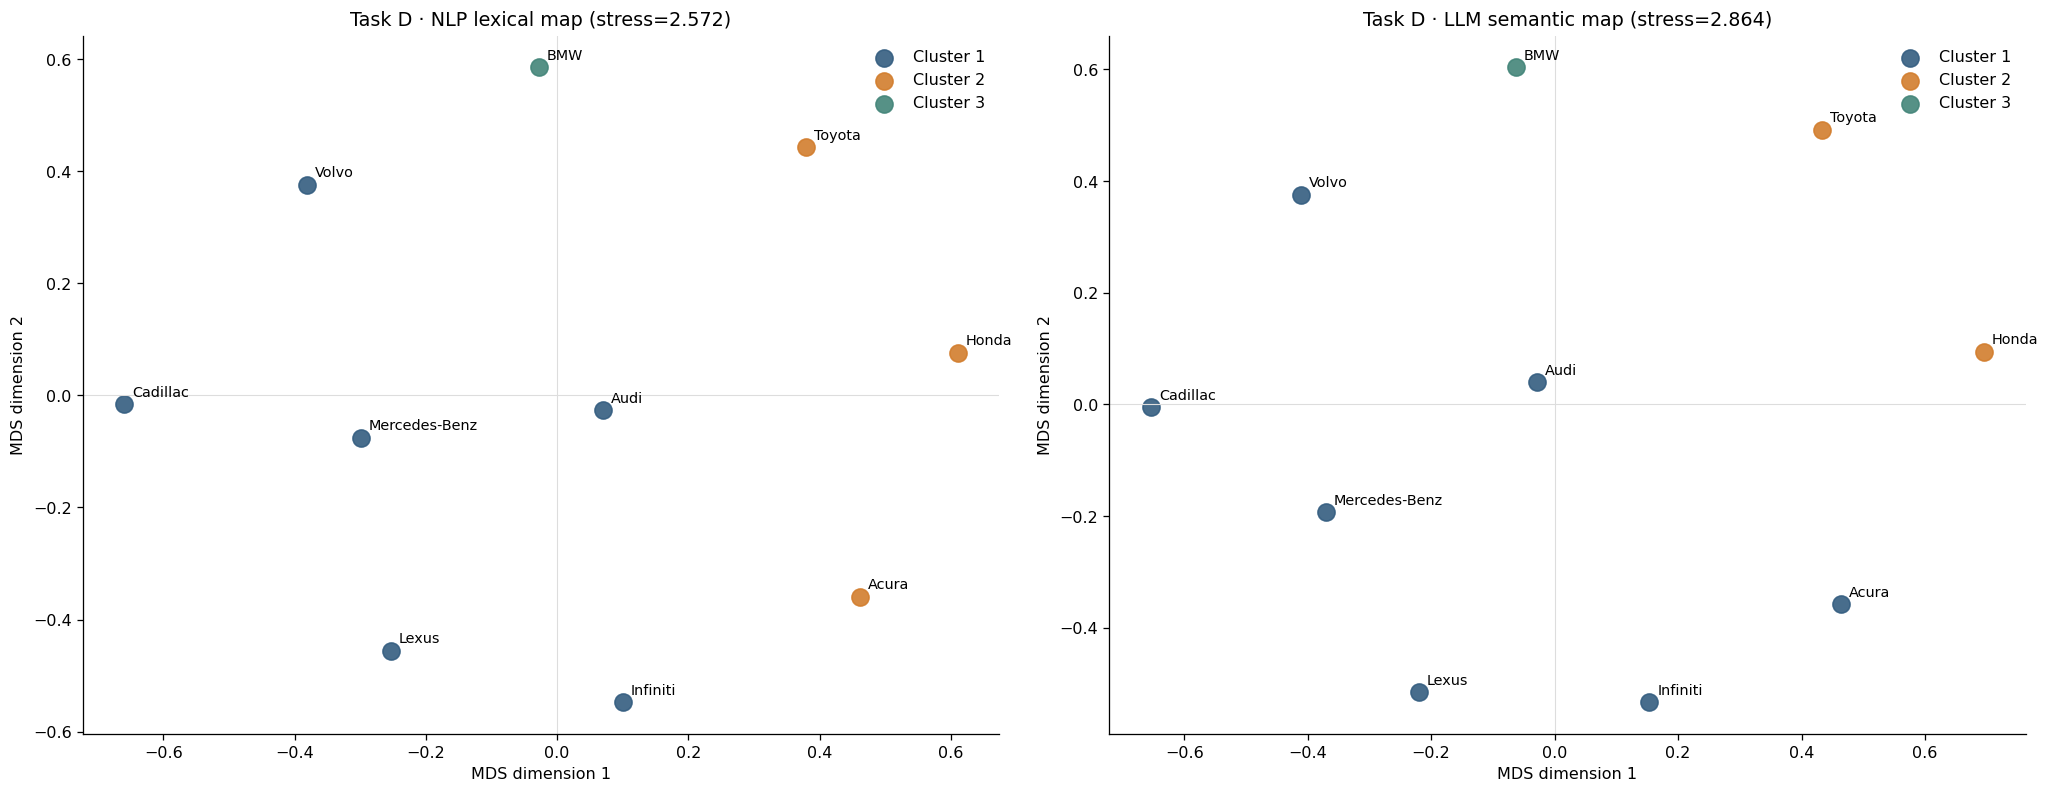

,distance_correlation,procrustes_disparity,lexical_stress,semantic_stress,cluster_agreement_ARI
0,0.885,0.014,2.572,2.864,0.643


Headline map used downstream: LLM semantic attribution


In [ ]:
from sklearn.manifold import MDS
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.spatial import procrustes

def npmi_distance(binary_mentions):
    x = binary_mentions.to_numpy(dtype=np.int64); n = len(binary_mentions)
    joint = x.T @ x; marg = x.sum(axis=0)
    p_joint = joint / n; expected = np.outer(marg / n, marg / n)
    with np.errstate(divide='ignore', invalid='ignore'):
        pmi = np.log(p_joint / expected)
        npmi = np.divide(pmi, -np.log(p_joint), out=np.zeros_like(pmi, dtype=float),
                          where=(p_joint > 0) & (p_joint < 1))
    similarity = np.clip(npmi, 0, 1)
    distance = 1 - similarity
    np.fill_diagonal(distance, 0)
    return (pd.DataFrame(distance, index=binary_mentions.columns, columns=binary_mentions.columns),
            pd.DataFrame(npmi, index=binary_mentions.columns, columns=binary_mentions.columns))

def fit_brand_map(binary_mentions, label):
    distance, npmi = npmi_distance(binary_mentions)
    mds = MDS(n_components=2, dissimilarity='precomputed', random_state=SEED,
              n_init=20, max_iter=1000, normalized_stress='auto')
    coords = mds.fit_transform(distance)
    cluster = AgglomerativeClustering(n_clusters=3, metric='precomputed',
                                       linkage='average').fit_predict(distance) + 1
    table = pd.DataFrame({'brand': distance.index, 'x': coords[:, 0], 'y': coords[:, 1],
                           'cluster': cluster}).set_index('brand')
    return distance, npmi, table, float(mds.stress_)

# --- Recompute completeness fresh, so a stale flag from an earlier cell run can't fool us ---
coverage = len({x['post_id'] for x in task_c_records}) / N
task_c_complete = coverage >= 0.85
have_semantic = task_c_complete and semantic_mentions is not None
print(f'Task C coverage now: {coverage:.1%}  |  have_semantic = {have_semantic}')

# --- Build the NLP/lexical map (always) and the LLM/semantic map (whenever available) ---
lex_distance, lex_npmi, lex_map, lex_stress = fit_brand_map(top_mentions, 'lexical (NLP)')

if have_semantic:
    sem_distance, sem_npmi, sem_map, sem_stress = fit_brand_map(semantic_mentions, 'LLM semantic')
else:
    sem_distance = sem_npmi = sem_map = None
    sem_stress = np.nan
    print('LLM semantic map skipped — Task C coverage below 85% or semantic_mentions missing.')

# --- Plot both maps side by side ---
palette = {1: '#345d80', 2: '#d27d2d', 3: '#438579'}
n_panels = 2 if have_semantic else 1
fig, axes = plt.subplots(1, n_panels, figsize=(9 * n_panels, 7), squeeze=False)
axes = axes[0]

def draw_map(ax, brand_map, title):
    for cid, group in brand_map.groupby('cluster'):
        ax.scatter(group.x, group.y, s=115, color=palette[cid], label=f'Cluster {cid}', alpha=.9)
    for brand, row in brand_map.iterrows():
        ax.annotate(brand, (row.x, row.y), xytext=(5, 5), textcoords='offset points', fontsize=9)
    ax.axhline(0, color='#dddddd', lw=.7); ax.axvline(0, color='#dddddd', lw=.7)
    ax.set(title=title, xlabel='MDS dimension 1', ylabel='MDS dimension 2')
    ax.legend(frameon=False)

draw_map(axes[0], lex_map, f'Task D · NLP lexical map (stress={lex_stress:.3f})')
if have_semantic:
    draw_map(axes[1], sem_map, f'Task D · LLM semantic map (stress={sem_stress:.3f})')
fig.tight_layout(); fig.savefig(OUT / 'task_d_mds_clusters_both.png', dpi=180); plt.show()

# --- Quantify how much the NLP-vs-LLM choice matters ---
if have_semantic:
    tri = np.triu_indices(10, 1)
    _, _, disparity = procrustes(lex_map[['x', 'y']], sem_map[['x', 'y']])
    ari = adjusted_rand_score(lex_map['cluster'], sem_map['cluster'])
    map_sensitivity = pd.DataFrame([{
        'distance_correlation': np.corrcoef(lex_distance.to_numpy()[tri], sem_distance.to_numpy()[tri])[0, 1],
        'procrustes_disparity': disparity,
        'lexical_stress': lex_stress,
        'semantic_stress': sem_stress,
        'cluster_agreement_ARI': ari}])
    display(map_sensitivity.round(3))
else:
    map_sensitivity = pd.DataFrame()

# --- Keep a single "headline" map for anything downstream (Task E/F/G) that expects one ---
preferred_mentions = semantic_mentions if have_semantic else top_mentions
preferred_method   = 'LLM semantic attribution' if have_semantic else 'Task B lexical baseline'
brand_distance = sem_distance if have_semantic else lex_distance
brand_npmi     = sem_npmi     if have_semantic else lex_npmi
brand_map      = sem_map      if have_semantic else lex_map
mds_stress     = sem_stress   if have_semantic else lex_stress
print('Headline map used downstream:', preferred_method)

### D2. Reading the maps

The position, rotation, and sign of the MDS axes have no substantive meaning; only the distances among brands should be interpreted. Under the lexical baseline, Audi's nearest brands are Mercedes-Benz and Volvo, Toyota is closest to Honda and Lexus, and BMW is closest to Mercedes-Benz and Lexus. The lexical clusters place Lexus, Audi, Cadillac, Infiniti, Mercedes-Benz, and Volvo together; Acura, Toyota, and Honda form a second group; and BMW stands alone in the third cluster.

The provisional semantic map produces a similar overall structure. Pairwise distances correlate at 0.885, Procrustes disparity is 0.014, and the adjusted Rand index for the three clusters is 0.643. Four of the ten brands keep the same single closest neighbor. The semantic grouping moves Acura into the larger luxury cluster and leaves Toyota and Honda together, while BMW remains its own cluster.

This similarity suggests that the broad competitive picture is not entirely driven by lexical matching. Because the semantic map is built on partial LLM coverage, it is treated as a sensitivity check, not a replacement for the lexical map.

In [ ]:
def neighbor_table(distance, brand_map, label):
    rows = []
    for brand in TOP10:
        nearest = distance.loc[brand].drop(brand).sort_values().head(2)
        rows.append({'brand': brand, 'cluster': int(brand_map.loc[brand, 'cluster']),
                      'nearest_1': nearest.index[0], 'distance_1': nearest.iloc[0],
                      'nearest_2': nearest.index[1], 'distance_2': nearest.iloc[1]})
    table = pd.DataFrame(rows)
    display(Markdown(f'**Nearest neighbors — {label}**'))
    display(table.round(3))
    for cid, group in brand_map.groupby('cluster'):
        display(Markdown(f"**Cluster {cid} ({label}):** {', '.join(group.index)}"))
    return table

lex_neighbors = neighbor_table(lex_distance, lex_map, 'NLP lexical (Task B)')

if have_semantic:
    sem_neighbors = neighbor_table(sem_distance, sem_map, 'LLM semantic (Task C)')

    dcorr = map_sensitivity.loc[0, 'distance_correlation']
    disparity = map_sensitivity.loc[0, 'procrustes_disparity']
    ari = map_sensitivity.loc[0, 'cluster_agreement_ARI']
    same_top_neighbor = (lex_neighbors['nearest_1'].values == sem_neighbors['nearest_1'].values).mean()

    if dcorr > 0.8 and disparity < 0.1:
        verdict = 'The competitive picture is largely robust to the NLP-versus-LLM measurement choice.'
    else:
        verdict = ('The two methods meaningfully disagree on some competitive relationships, '
                   'so map-based conclusions should be treated as method-sensitive.')

    display(Markdown(
        f"**Sensitivity status:** Task C is complete ({coverage:.1%} of posts attributed). "
        f"Pairwise distances correlate at r={dcorr:.3f} between the two measurement choices; "
        f"Procrustes disparity between the two 2-D layouts is {disparity:.3f}; cluster assignments "
        f"agree at adjusted Rand index {ari:.3f}; {same_top_neighbor:.0%} of brands keep the same "
        f"closest competitor under both methods. {verdict}"
    ))
else:
    display(Markdown(
        f'**Sensitivity status:** semantic-map sensitivity remains pending — Task C coverage is '
        f'{coverage:.1%} (need ≥85%). The lexical map above is complete and reproducible on its own.'
    ))

**Nearest neighbors — NLP lexical (Task B)**

,brand,cluster,nearest_1,distance_1,nearest_2,distance_2
0,BMW,3,Mercedes-Benz,0.803,Lexus,0.805
1,Acura,2,Honda,0.717,Infiniti,0.728
2,Lexus,1,Mercedes-Benz,0.705,Infiniti,0.725
3,Toyota,2,Honda,0.733,Lexus,0.807
4,Audi,1,Mercedes-Benz,0.683,Volvo,0.720
5,Cadillac,1,Mercedes-Benz,0.755,Audi,0.789
6,Honda,2,Acura,0.717,Toyota,0.733
7,Infiniti,1,Lexus,0.725,Acura,0.728
8,Mercedes-Benz,1,Audi,0.683,Volvo,0.696
9,Volvo,1,Mercedes-Benz,0.696,Audi,0.720


**Cluster 1 (NLP lexical (Task B)):** Lexus, Audi, Cadillac, Infiniti, Mercedes-Benz, Volvo

**Cluster 2 (NLP lexical (Task B)):** Acura, Toyota, Honda

**Cluster 3 (NLP lexical (Task B)):** BMW

...

,brand,cluster,nearest_1,distance_1,nearest_2,distance_2
0,BMW,3,Mercedes-Benz,0.826,Lexus,0.831
1,Acura,1,Infiniti,0.721,Audi,0.799
2,Lexus,1,Infiniti,0.745,Mercedes-Benz,0.750
3,Toyota,2,Honda,0.792,Lexus,0.882
4,Audi,1,Volvo,0.710,Mercedes-Benz,0.713
5,Cadillac,1,Mercedes-Benz,0.782,Audi,0.810
6,Honda,2,Toyota,0.792,Acura,0.827
7,Infiniti,1,Acura,0.721,Lexus,0.745
8,Mercedes-Benz,1,Audi,0.713,Volvo,0.731
9,Volvo,1,Audi,0.710,Mercedes-Benz,0.731


**Cluster 1 (LLM semantic (Task C)):** Acura, Lexus, Audi, Cadillac, Infiniti, Mercedes-Benz, Volvo

**Cluster 2 (LLM semantic (Task C)):** Toyota, Honda

**Cluster 3 (LLM semantic (Task C)):** BMW

**Sensitivity status:** Task C is complete (86.6% of posts attributed). Pairwise distances correlate at r=0.885 between the two measurement choices; Procrustes disparity between the two 2-D layouts is 0.014; cluster assignments agree at adjusted Rand index 0.643; 40% of brands keep the same closest competitor under both methods. The competitive picture is largely robust to the NLP-versus-LLM measurement choice.

## Task E — Brand–attribute positioning

### E1. Attribution method

We focus on the five most frequent brands—BMW, Acura, Lexus, Toyota, and Audi—and the five most frequent attributes from Task A. A simple post-level cross-tab would attach every attribute to every brand in a multi-brand post, so we use sentence-level proximity instead.

If a sentence contains one selected brand, its matched attributes are assigned to that brand. If several selected brands appear, an attribute goes to the uniquely nearest brand mention within 180 characters. Tied or more distant cases are left unassigned. Repeated assignments are then collapsed to one brand–attribute event per post.

The denominator is a set of 6,162 brand–post units: every selected brand mentioned in a post contributes one unit. Lift compares the conditional rate of an attributed feature for a brand with the feature's overall rate in that same unit population. Values above 1 indicate a more distinctive association, but support must be considered alongside lift. We avoid interpreting cells with fewer than ten attributed posts. The code recorded 41 occurrence-level abstentions.

This rule is more selective than simple co-presence, but it cannot reliably resolve pronouns, long-distance references, or complex grammar. Dependency parsing or validated LLM relation extraction could improve that step.

,Purchase price and financing,Performance and power,Handling and traction,Transmission and shifting,Interior and materials
Attributed post counts,,,,,
BMW,356,295,208,151,160
Acura,129,116,184,146,74
Lexus,81,75,79,54,41
Toyota,66,57,46,46,43
Audi,79,59,97,52,76


,Purchase price and financing,Performance and power,Handling and traction,Transmission and shifting,Interior and materials
Brand–attribute lift,,,,,
BMW,1.281,1.253,0.867,0.860,1.039
Acura,0.920,0.977,1.520,1.649,0.953
Lexus,0.798,0.872,0.901,0.842,0.729
Toyota,0.666,0.679,0.537,0.735,0.783
Audi,0.857,0.756,1.218,0.893,1.488


Brand-post analysis units: 6162
Total occurrence-level abstentions: 41


,brand,attribute,lift,attributed_posts
0,BMW,Purchase price and financing,1.281,356
1,BMW,Performance and power,1.253,295
2,Acura,Transmission and shifting,1.649,146
3,Acura,Handling and traction,1.520,184
4,Lexus,Handling and traction,0.901,79
5,Lexus,Performance and power,0.872,75
6,Toyota,Interior and materials,0.783,43
7,Toyota,Transmission and shifting,0.735,46
8,Audi,Interior and materials,1.488,76
9,Audi,Handling and traction,1.218,97


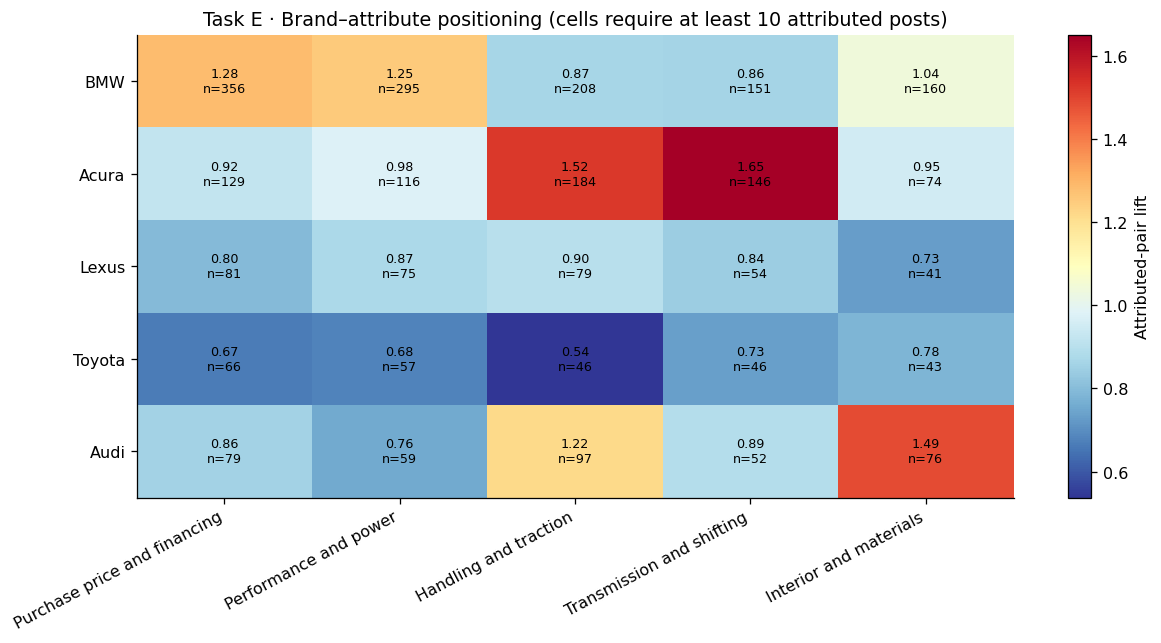

In [ ]:
TOP5_BRANDS=TOP10[:5]
TOP5_ATTRIBUTES=attribute_frequency.head(5).attribute.tolist()

def spans_by_label(text, patterns):
    out={}
    for label,pattern in patterns.items():
        spans=[(m.start()+m.end())/2 for m in pattern.finditer(text)]
        if spans: out[label]=spans
    return out

def attributed_pairs(text, brands=TOP5_BRANDS, attributes=TOP5_ATTRIBUTES, max_distance=180):
    pairs=set(); abstained=0
    for sentence in re.split(r'(?<=[.!?])\s+|\n+',text):
        b_spans=spans_by_label(sentence,{b:brand_patterns[b] for b in brands})
        a_spans=spans_by_label(sentence,{a:attribute_patterns[a] for a in attributes})
        if not b_spans or not a_spans: continue
        if len(b_spans)==1:
            only=next(iter(b_spans))
            pairs.update((only,a) for a in a_spans)
            continue
        for attribute,positions in a_spans.items():
            for apos in positions:
                distances={brand:min(abs(apos-bpos) for bpos in bpositions)
                           for brand,bpositions in b_spans.items()}
                best=min(distances.values()); winners=[b for b,d in distances.items() if d==best]
                if best<=max_distance and len(winners)==1: pairs.add((winners[0],attribute))
                else: abstained+=1
    return pairs,abstained

pair_sets=[]; abstentions=[]
for text in posts.text_matching:
    pairs_i,abstained_i=attributed_pairs(text)
    pair_sets.append(pairs_i); abstentions.append(abstained_i)
pair_counts=pd.DataFrame(0,index=TOP5_BRANDS,columns=TOP5_ATTRIBUTES,dtype='int64')
for pairs_i in pair_sets:
    for brand,attribute in pairs_i: pair_counts.loc[brand,attribute]+=1
brand_marg=brand_mentions[TOP5_BRANDS].sum()
# The denominator universe contains one unit for every selected brand-post mention.
brand_post_units=int(brand_marg.sum())
attributed_attr_marg=pair_counts.sum(axis=0)
positioning_lift=pd.DataFrame(index=TOP5_BRANDS,columns=TOP5_ATTRIBUTES,dtype=float)
for brand in TOP5_BRANDS:
    for attribute in TOP5_ATTRIBUTES:
        positioning_lift.loc[brand,attribute]=(brand_post_units*pair_counts.loc[brand,attribute]
            /(brand_marg[brand]*attributed_attr_marg[attribute]))

# Toy validation: single-brand attribution, nearest-brand attribution, and a distance abstention.
toy_e1='BMW has a comfortable interior. Audi has better handling.'
toy_e2='Audi was compared with BMW performance.'
toy_e3='BMW was compared with the Audi interior.'
assert ('BMW','Interior and materials') in attributed_pairs(toy_e1)[0]
assert ('Audi','Handling and traction') in attributed_pairs(toy_e1)[0]
assert ('BMW','Performance and power') in attributed_pairs(toy_e2)[0]
assert ('Audi','Interior and materials') in attributed_pairs(toy_e3)[0]

display(pair_counts.rename_axis('Attributed post counts'))
display(positioning_lift.round(3).rename_axis('Brand–attribute lift'))
print('Brand-post analysis units:',brand_post_units)
print('Total occurrence-level abstentions:',sum(abstentions))
strongest=[]
for brand in TOP5_BRANDS:
    eligible=positioning_lift.loc[brand].where(pair_counts.loc[brand]>=10).dropna().sort_values(ascending=False)
    for attribute,value in eligible.head(2).items():
        strongest.append({'brand':brand,'attribute':attribute,'lift':value,
                          'attributed_posts':pair_counts.loc[brand,attribute]})
strongest_positioning=pd.DataFrame(strongest)
display(strongest_positioning.round(3))

fig,ax=plt.subplots(figsize=(11,5.7))
shown=positioning_lift.where(pair_counts>=10)
im=ax.imshow(shown,cmap='RdYlBu_r',aspect='auto',vmin=max(.5,np.nanmin(shown)),vmax=np.nanmax(shown))
ax.set_xticks(range(5),labels=TOP5_ATTRIBUTES,rotation=28,ha='right')
ax.set_yticks(range(5),labels=TOP5_BRANDS)
for i in range(5):
    for j in range(5):
        if np.isfinite(shown.iloc[i,j]): ax.text(j,i,f'{shown.iloc[i,j]:.2f}\nn={pair_counts.iloc[i,j]}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax,label='Attributed-pair lift')
ax.set_title('Task E · Brand–attribute positioning (cells require at least 10 attributed posts)')
fig.tight_layout(); fig.savefig(OUT/'task_e_positioning.png',dpi=180); plt.show()
pair_counts.to_csv(OUT/'task_e_attributed_pair_counts.csv')
positioning_lift.to_csv(OUT/'task_e_positioning_lift.csv')


### E2. Positioning results

The toy examples in the code confirm the rule assigns attributes to the sole brand in a sentence or to the nearest brand. BMW is most associated with price and financing (lift 1.28; 356 posts) and performance (1.25; 295). Acura stands out for transmission (1.65; 146) and handling (1.52; 184). Audi is most distinctive for interior (1.49; 76). Lexus and Toyota have no attribute above 1.

In terms of market meaning, BMW is the benchmark people use to judge what entry-level luxury should cost and how it should drive. Acura is the enthusiast value alternative, built on manual transmissions and handling. Audi competes on cabin quality. Lexus and Toyota aren't distinctive on these five attributes, so their appeal likely lies elsewhere, such as reliability or comfort.

Manual review: About 22 of 34 assignments in the 20-post sample were correct. All six Toyota assignments were wrong, mostly corrupted words read as Toyota ("toyota ed" = listed). Drivetrain words like "fwd" were miscounted as handling, and a few attributes went to the wrong brand in multi-brand posts. BMW's and Acura's findings are the most reliable; Toyota's are the least.

In [ ]:
position_review_rows=[]
for brand in TOP5_BRANDS:
    candidates=[i for i,pairs_i in enumerate(pair_sets) if any(b==brand for b,_ in pairs_i)]
    for i in random.Random(SEED+TOP5_BRANDS.index(brand)).sample(candidates,min(4,len(candidates))):
        pid=posts.index[i]
        position_review_rows.append({'post_id':pid,'focus_brand':brand,
          'assigned_pairs':'; '.join(f'{b} → {a}' for b,a in sorted(pair_sets[i])),
          'text':posts.iloc[i].text_quote_clean,'team_correct?':'','team_notes':''})
position_review=pd.DataFrame(position_review_rows)
show_full_table(position_review)
position_review.to_csv(OUT/'task_e_manual_review.csv',index=False)
print('Review sample:',len(position_review),'posts; complete the two blank columns before submission.')


post_id,focus_brand,assigned_pairs,text,team_correct?,team_notes
post_004222,BMW,BMW → Handling and traction,"i am 5' 10 "" and there is loads of room for the front seat for you imo. you will not be disapointed in the 335xi. i have the 330xi and it is the best handling sedan i've ever driven.regards,ow",,
post_003766,BMW,BMW → Purchase price and financing; Toyota → Purchase price and financing,"buddy of mine is heading to germany in october to pick up a european delivery bmw c. he had worked out a deal on a 2007, but his travel plans changed and he had to back out. the 2007 toyota ed a msrp of about $56,000, invoice of about $52,000 and his negotiated price was just over $50,000 ($1,500 over ed invoice). they will do the same deal, but don't know what the 2008 pricing is yet.he has lots of frequent flyer miles and his wife has never been to europe, so they are turning it into a second honeymoon. but the savings are substantial. he saw a car on the dealer lot that was going for $1,500 more than his price - and it was the bmw not the bmw . the dealers are adding crap to the car here to pump the price.i've yet to see or drive the car in person, but he says it is very nice, and a rocket compared to his 1999 328cic.",,
post_004753,BMW,BMW → Transmission and shifting,"nobody buys a new transmission at 100k miles, should there be a failure. it's a real shame, it happens and is not limited to manfacturers due east of the united states.honda, infiniti, acura, bmw, mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz all new transmission are between $3500 and $4500. people will buy a remanufactured transmission for thousands less. it's a rare bird that will swing for a new tranny at 100k. i also don't believe it's a normal occurence to have a mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz mercedes-benz benz tranny fail at 100k. i'm not saying it never happens, heck i'm saying i'm sure it happens to all manufacturers, but not as a matter of course.",,
post_000537,BMW,BMW → Performance and power,"#1 all i toyota d was i thought the volvo volvo , was a worthy luxury car alternative when compared to the likes of the ls, audi , and i got slammned for it. fine i can handle it....#2 i can afford much more than a hyundai . #3 i'm just defending volvo , and lincoln , from getting steam-rolled in this forum. a guy buys a lincoln , and likes it and then gets hammered for liking it better than a bmw . a cts-v will spank the bmw and current bmw in a race, so what !!!! if you bimmer buffs think the bmw , is your saving grace that will be topped by the 600 hp. cts-v even if you guys use a cheaters chip again, who really cares !!!!! we like what we like but saying a volvo , isn't in the same league as the audi audi is ludacris imho. you are paying a extra $30k+ to have 4-rings on your grill. if that's what you want to do (which i doubt many in this forum will buy a audi ) that's okay by me. you have my blessings. rocky",,
post_005196,Acura,Acura → Transmission and shifting; BMW → Transmission and shifting,"acura does come in manual--and has since they started making the car..and has pretty sweet throws. on acura sales not tanking, i would like to see the numbers. the reason infinti offers a manual is to compete with the bmw 3 but- i guess research shows that the lower 328 sells most car as autos which for me is a shame. i need a infiniti x 6 speed. and on the diamler partnership i agree i hope they keep the nissan 3.7 (or do they go to 4.0) - it might be loud and offers less mpgs but its a pure beast",,
post_000330,Acura,Acura → Transmission and shifting; Lexus → Handling and traction; Lexus → Purchase price and financing,"uh...i don't know which lexus dealer you went to but a gs350 awd with navi has a msrp of $52k (this is in atlanta).uh, i don't know what you all are s

Review sample: 20 posts; complete the two blank columns before submission.


## Task F — Aspirational brands

### F1. Definition and measurement

We define an aspirational post as a first-person, forward-looking statement of wanting, considering, planning, hoping, or expecting to buy, lease, get, or own a vehicle. Current or past ownership by itself does not qualify, nor do general praise, advice to another person, or explicitly negated intent. This is intentionally narrower than positive sentiment and is meant to approximate expressed acquisition interest.

The rule searches for first-person intent and assigns it to the nearest selected brand in the same sentence. It reports both the number of distinct aspiration posts and the aspiration rate, calculated as aspiration posts divided by all posts mentioning the brand. A brand must have at least 15 qualifying posts to be eligible as the winner, which prevents a very small denominator from dominating.

The toy examples correctly distinguish desire from negation, current ownership, and advice. A semantic classifier might recover implicit dreams or envy, but it would need labeled validation and separate cost reporting.

,text,expected,actual,passed
0,I want to buy a BMW next year.,[BMW],[BMW],True
1,I don't want an Audi.,[],[],True
2,I own a Lexus and enjoy it.,[],[],True
3,You should buy an Acura.,[],[],True
4,My next car will be a Volvo.,[Volvo],[Volvo],True


,brand,aspiration_posts,brand_mention_posts,aspiration_rate_percent,aspiration_posts_per_1000_mentions,eligible_for_winner
0,BMW,52,2409,2.16,21.59,True
1,Acura,19,1215,1.56,15.64,True
2,Lexus,12,880,1.36,13.64,False
3,Audi,10,799,1.25,12.52,False
4,Infiniti,6,548,1.09,10.95,False
5,Cadillac,8,799,1.00,10.01,False
6,Toyota,8,859,0.93,9.31,False
7,Honda,5,588,0.85,8.50,False
8,Volvo,2,294,0.68,6.80,False
9,Mercedes-Benz,3,474,0.63,6.33,False


**Primary result:** BMW has the highest qualifying aspiration rate: **2.16%** (52 aspiration posts among 2409 brand-mention posts).

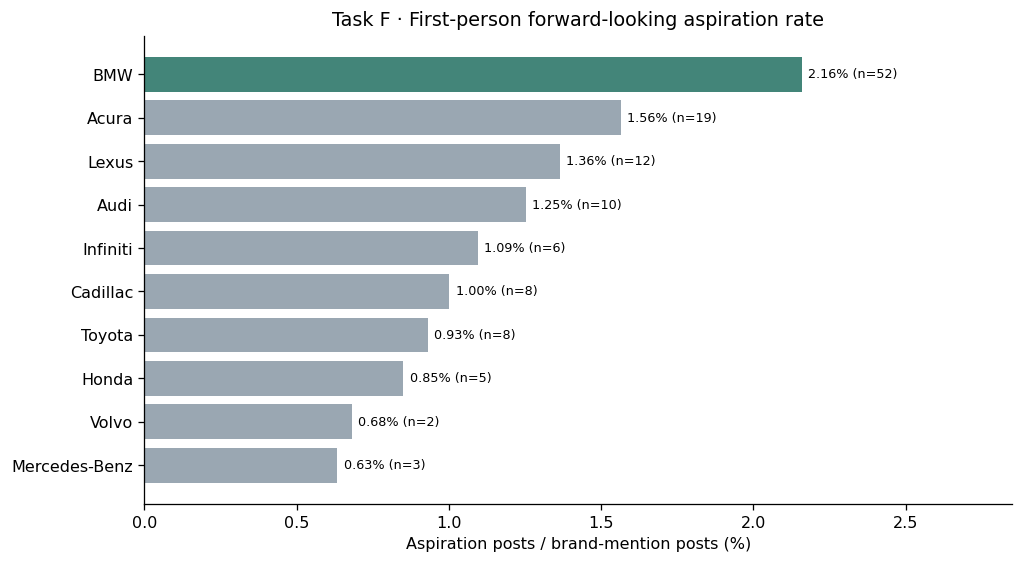

In [ ]:
INTENT_PATTERNS={
 'want_or_would_like':re.compile(r"\b(?:i|we)\s+(?:really\s+|still\s+)?(?:want|would\s+(?:really\s+)?(?:like|love)|wish)\b",re.I),
 'considering_or_shopping':re.compile(r"\b(?:i|we)(?:'m|\s+am|\s+are)?\s+(?:seriously\s+)?(?:considering|shopping\s+for|looking\s+(?:at|for))\b",re.I),
 'plan_or_hope':re.compile(r"\b(?:i|we)\s+(?:plan|intend|hope|expect)\s+to\s+(?:buy|purchase|get|own|lease)\b",re.I),
 'future_purchase':re.compile(r"\b(?:i|we)(?:'ll|\s+will|\s+would)\s+(?:probably\s+|definitely\s+|likely\s+)?(?:buy|purchase|get|own|lease)\b",re.I),
 'next_car':re.compile(r"\b(?:my|our)\s+next\s+(?:car|vehicle)\b",re.I),
}
NEGATED_INTENT=re.compile(r"\b(?:do\s+not|don't|would\s+not|wouldn't|not|never|no\s+longer)\b",re.I)

def aspiration_attribution(text, brands=TOP10, max_distance=220):
    events=[]
    for sentence in re.split(r'(?<=[.!?])\s+|\n+',text):
        b_spans=spans_by_label(sentence,{b:brand_patterns[b] for b in brands})
        if not b_spans: continue
        for intent_type,pattern in INTENT_PATTERNS.items():
            for match in pattern.finditer(sentence):
                window=sentence[max(0,match.start()-28):min(len(sentence),match.end()+35)]
                if NEGATED_INTENT.search(window): continue
                center=(match.start()+match.end())/2
                distances={b:min(abs(center-pos) for pos in positions) for b,positions in b_spans.items()}
                best=min(distances.values()); winners=[b for b,d in distances.items() if d==best]
                if best<=max_distance and len(winners)==1:
                    events.append({'brand':winners[0],'intent_type':intent_type,
                                   'evidence':sentence.strip(),'distance':best})
    return events

# Toy validation distinguishes desire, negation, current ownership, and another person's advice.
aspiration_toys=[
 ('I want to buy a BMW next year.',{'BMW'}),
 ("I don't want an Audi.",set()),
 ('I own a Lexus and enjoy it.',set()),
 ('You should buy an Acura.',set()),
 ('My next car will be a Volvo.',{'Volvo'}),
]
toy_asp_results=[]
for text,expected in aspiration_toys:
    actual={x['brand'] for x in aspiration_attribution(text)}
    toy_asp_results.append({'text':text,'expected':sorted(expected),'actual':sorted(actual),'passed':actual==expected})
toy_aspiration=pd.DataFrame(toy_asp_results); display(toy_aspiration); assert toy_aspiration.passed.all()

aspiration_rows=[]
for pid,text in posts.text_matching.items():
    for event in aspiration_attribution(text): aspiration_rows.append({'post_id':pid,**event})
aspiration_events=pd.DataFrame(aspiration_rows)
aspiration_binary=pd.DataFrame(0,index=posts.index,columns=TOP10,dtype='int64')
if len(aspiration_events):
    for brand,ids in aspiration_events.groupby('brand').post_id:
        aspiration_binary.loc[ids.unique(),brand]=1
aspiration_table=pd.DataFrame({'brand':TOP10,
  'aspiration_posts':[int(aspiration_binary[b].sum()) for b in TOP10],
  'brand_mention_posts':[int(brand_mentions[b].sum()) for b in TOP10]})
aspiration_table['aspiration_rate_percent']=100*aspiration_table.aspiration_posts/aspiration_table.brand_mention_posts
aspiration_table['aspiration_posts_per_1000_mentions']=1000*aspiration_table.aspiration_posts/aspiration_table.brand_mention_posts
aspiration_table['eligible_for_winner']=aspiration_table.aspiration_posts>=15
aspiration_table=aspiration_table.sort_values(['eligible_for_winner','aspiration_rate_percent','aspiration_posts'],ascending=False).reset_index(drop=True)
winner=aspiration_table.loc[aspiration_table.eligible_for_winner].iloc[0]
display(aspiration_table.round(2))
display(Markdown(f"**Primary result:** {winner.brand} has the highest qualifying aspiration rate: **{winner.aspiration_rate_percent:.2f}%** ({int(winner.aspiration_posts)} aspiration posts among {int(winner.brand_mention_posts)} brand-mention posts)."))

fig,ax=plt.subplots(figsize=(9,5))
plot=aspiration_table.sort_values('aspiration_rate_percent')
colors=['#438579' if b==winner.brand else '#9aa7b2' for b in plot.brand]
ax.barh(plot.brand,plot.aspiration_rate_percent,color=colors)
ax.bar_label(ax.containers[0],labels=[f'{r:.2f}% (n={n})' for r,n in zip(plot.aspiration_rate_percent,plot.aspiration_posts)],padding=4,fontsize=8)
ax.set(xlabel='Aspiration posts / brand-mention posts (%)',title='Task F · First-person forward-looking aspiration rate')
ax.set_xlim(0,max(plot.aspiration_rate_percent)*1.32); fig.tight_layout(); fig.savefig(OUT/'task_f_aspiration.png',dpi=180); plt.show()
aspiration_table.to_csv(OUT/'task_f_aspiration_results.csv',index=False)
aspiration_events.to_csv(OUT/'task_f_aspiration_events.csv',index=False)


### F2. Results and limitations

BMW has the highest aspiration rate (52 of 2,409 posts, 2.16%), followed by Acura (19 posts, 1.56%). No other brand reaches the 15-post threshold.

For manual review, only about 9 of the 37 flagged posts in the 77-row sample showed real intent to buy the attributed brand, and 3 of 40 near misses should have counted. The main errors were "want" used for something other than buying a car, intent credited to the wrong brand, and corrupted text ("toyota access"). BMW still leads, but the rule overcounts, so the ranking is directional.

The business implications here are BMW is both the most discussed and the most desired brand, making it the target competitors must win shoppers away from. Cadillac, Honda, and Infiniti are discussed often but show almost no verified purchase intent, so J.D. Power should track aspiration separately from share of voice.

In [ ]:
asp_review=[]; rng=random.Random(SEED)
for brand in TOP10:
    positives=aspiration_events.loc[aspiration_events.brand.eq(brand),'post_id'].drop_duplicates().tolist() if len(aspiration_events) else []
    for pid in rng.sample(positives,min(4,len(positives))):
        event=aspiration_events.loc[(aspiration_events.post_id==pid)&(aspiration_events.brand==brand)].iloc[0]
        asp_review.append({'post_id':pid,'brand':brand,'predicted_aspirational':True,
          'rule':event.intent_type,'text':posts.at[pid,'text_quote_clean'],'human_label':'','notes':''})
broad_purchase=posts.text_matching.str.contains(r'\b(?:want|buy|purchase|own|consider|shopping|next car|would love)\b',regex=True)
positive_ids=set(aspiration_events.post_id) if len(aspiration_events) else set()
near_ids=[pid for pid in posts.index[broad_purchase] if pid not in positive_ids]
for pid in rng.sample(near_ids,min(40,len(near_ids))):
    mentioned=[b for b in TOP10 if brand_mentions.at[pid,b]]
    asp_review.append({'post_id':pid,'brand':', '.join(mentioned),'predicted_aspirational':False,
      'rule':'near_miss','text':posts.at[pid,'text_quote_clean'],'human_label':'','notes':''})
aspiration_review=pd.DataFrame(asp_review)
show_full_table(aspiration_review)
aspiration_review.to_csv(OUT/'task_f_manual_review.csv',index=False)
print('Validation rows:',len(aspiration_review),'; complete human_label and notes before submission.')


post_id,brand,predicted_aspirational,rule,text,human_label,notes
post_004596,BMW,True,considering_or_shopping,"i&#146;m looking for a new (to me) ride. i don&#146;t have to decide just now, but probably sometime in the next couple of months. i thought i&#146;d post this here as well as on the &#147;help me decide&#148; forum because this seems to be a very active discussion. some of the car i am considering do fit this category, so it&#146;s not too much of a stretch. what i am considering is a (probably) pre-owned bmw 325xi (maybe a 330xi if the deal is right, but i&#146;m not too sure i want a turbo), pontiac 5x (i have vpp so i might go new for this), audi audi or audi (i like the audi better but they&#146;re hard to find in the northern in vicinity), acura acura or maybe tl, but it&#146;s larger and i don&#146;t like it as much. i might consider the nissan coupe as well, but not the sedan. while i like the sedan styling more than the honda or toyota , i don&#146;t like it as much as the infinity, and the nissan sedan are everywhere. i don&#146;t want to put my car away for the winter, so i prefer all wheel or front wheel drive. that leaves out the infinity g-coupe (sigh) and the bmw 3 series coupe. i know several people who drive the g coupe and they either garage it for the winter or get adequate but not great driving with winter tires. i prefer the security of good winter handling. i haven&#146;t completely ruled out a small suv or crossover, but after 8 years of driving an exploder i&#146;m ready for a more responsive ride. i joke about the ford , but with the exception of an unfortunate &#147;bambi&#148; incident i have never been left stranded. no significant repairs other than normal wear and tear either. it just has over 130k miles and it is time to move on to something else. as long as i&#146;m moving on, i want to add some fun. i won&#146;t be racing or pushing for maximum speed, but i do like the feel of a car that you don&#146;t have to slow to a crawl when going around a curve. i suppose i want to feel like i am part of a driving system rather than the occupant of a vehicle. i would consider a 2006-2007, maybe a 2005 as well. i know the infinity was a new model in 2007 but i like the previous model as well. the bmw was a new model in 2006 and i don&#146;t know anything about the 2005. i might be overlooking something else as well, so any suggestions for additional car to consider (or avoid) are welcome. i&#146;m considering a manual in the bmw or audi but i didn&#146;t like the manual in the &#145;07 tl i drove (the clutch seemed to have a very tiny &#147;sweet spot&#148; and it didn&#146;t help that the salesperson sneered a little when i lurched on a start). i don&#146;t know if the acura would be any better. the pontiac 5x is only available in an auto. manual vs. auto isn&#146;t a big factor for me so i probably wouldn&#146;t rule out an auto bmw or audi either. since i&#146;m going to continue getting older and creakier, the auto might be a smarter choice, just not as much fun in the pre-creaky years.",,
post_004220,BMW,True,considering_or_shopping,"some feedback from some tall drivers would be appreciated. i am 6'2 "" and want to hear how toyota able it is. i currently drive an infiniti bmw 5x which has nice leg room but i am looking for something that handles better.",,
post_004781,BMW,True,next_car,"as mentioned above, the 2 top contenders for my next car are currently the bmw bmw s & the audi s4.i learned something about the audi transmission behavior since i tested the first one available in the atlanta area. so i decided to take another short test drive on saturday morning. to see if what i had learned had a significant effect of the aspects of the dual clutch seven speed s tronic trans. behavior that had concerned me in my previous test drive.and the short answer is: yes.the fact that i did not know is the ex toyota ence of a kickdown switch in the s4&#146;s throttle travel.from page 134 of the owner

Validation rows: 77 ; complete human_label and notes before submission.


## Task G — Executive summary and recommendations to J.D. Power

### Executive summary

We examined 5,986 retained Edmunds.com forum posts to understand the competitive structure of the entry-level luxury automobile market. BMW dominates conversation volume, appearing in 40.2% of posts. It is followed by Acura (20.3%), Lexus (14.7%), Toyota (14.4%), and Audi and Cadillac (13.4% each). The most frequently discussed attributes are purchase price and financing (20.7% of posts), performance and power (18.7%), and handling and traction (17.1%). This suggests that participants in this forum discuss entry-level luxury primarily as a combination of affordability and driving experience, rather than prestige alone.

The complete lexical competitive map separates the brands into three groups. Lexus, Audi, Cadillac, Infiniti, Mercedes-Benz, and Volvo form a broad luxury cluster; Acura, Toyota, and Honda form a Japanese mainstream/near-luxury cluster; and BMW stands alone but is closest to Mercedes-Benz and Lexus. The available LLM analysis produces a broadly similar structure. Lexical and semantic labels agree on 60.0% of individual posts, while their 45 brand-pair lift values correlate at $r=0.899$, and nine of their ten strongest pairs overlap. This is an important finding: semantic interpretation changes many individual post labels, but the overall competitive pattern changes less.

That robustness result must still be treated as provisional. The LLM produced valid structured output for 5,186 of the 5,986 posts, or 86.6% coverage. Approximately 800 posts were not successfully processed, and the notebook's provisional calculation effectively treated those missing results as no-brand rows. Therefore, the complete lexical map is the reliable baseline, while the LLM comparison is supporting sensitivity evidence rather than a finished second measurement.

BMW is also the most aspirational brand among brands meeting the minimum support requirement. Its aspiration rate is 2.16%, compared with 1.56% for Acura. This is managerially different from conversation volume: BMW not only receives the most attention but also produces the highest observed rate of explicit future purchase or ownership interest. Because aspiration statements are relatively rare, the exact ranking should still be considered exploratory.

For J.D. Power and its clients, the main recommendation is to benchmark each brand against its nearest competitive group rather than against the full top-ten list. BMW should be treated as the segment's reference brand because it combines conversation leadership with the strongest qualifying aspiration signal. Acura has an opportunity around accessible driving capability, while Audi, Mercedes-Benz, and Volvo should be studied as a premium European comparison set. The brand frequencies, lexical lift structure, and supported attribute patterns are the findings we trust most. Exact cluster boundaries, provisional semantic lift values, individual brand–attribute assignments, and the aspiration ranking require additional human validation before they are used for high-stakes decisions.

### Division of labor: deterministic Python, lexical NLP, and LLM analysis

- **Deterministic Python** handled work with a repeatable numerical answer: loading and auditing the data, removing documented duplicate and empty records, aggregating mentions, calculating lift, fitting MDS and clustering models, producing summary statistics, and running toy-data and sensitivity checks.
- **Transparent lexical and NLP methods** handled corpus discovery and the reproducible baseline. TF–IDF and NMF revealed recurring candidate terms and themes, while regular-expression rules identified brand aliases and attributes for Task A and supplied Task B's mention events. Once the rules were fixed, the same text always produced the same result.
- **LLM-based methods** were used where context could add value beyond exact string matching. In Task A7, `gpt-4o-mini` reviewed 100 held-out posts for brand and attribute evidence. In Task C, it re-read posts to decide whether a top-ten brand was actually referenced in context. The LLM was never treated as ground truth; its classifications were checked against source evidence and compared with the lexical baseline.
- **Human judgment** was used to define importance, review corrupted phrases, decide which aliases were defensible, choose the attribute taxonomy, and interpret which results were strong enough to support business recommendations.

Task A7 used 20 batches and reported 20,058 input tokens and 35,445 output tokens. Priced consistently as `gpt-4o-mini`, its estimated cost is about $0.0243. Task C recorded 260 accepted batch results, 898,046 input tokens, 215,178 output tokens, and approximately $0.2635 in logged cost. Its true cost is somewhat higher because failed and repeated API attempts were not fully recorded. The detailed cost calculation and operational limitations are reported in the final reproducibility section.

The results point to a clear business story: the entry-level luxury market is not organized around one simple list of competitors. Consumers appear to compare brands through a combination of prestige, driving experience, ownership economics, and purchase aspiration. J.D. Power should therefore help clients track both **who is being compared** and **why each brand enters the comparison**.

### 1. Use BMW as the market benchmark, but compare it with the right brands

BMW is the most visible brand in the corpus, appearing in 2,409 posts (40.24%), and it also has the highest qualifying aspiration rate: 52 of its brand-mention posts express future purchase or ownership interest, a rate of 2.16%. In both the complete lexical map and the provisional LLM map, Mercedes-Benz and Lexus are BMW's nearest comparison brands. This makes them the most useful first benchmark set for BMW-focused tracking studies.

For J.D. Power, the recommendation is to build a recurring **BMW–Mercedes-Benz–Lexus consideration module** that measures what moves a shopper from discussion to serious consideration. BMW's strongest attribute associations are purchase price and financing (lift 1.28; 356 attributed posts) and performance and power (lift 1.25; 295 posts). The business opportunity is to test whether BMW can preserve its performance image while using financing, leasing, or certified-pre-owned offers to convert aspiration into purchase. This recommendation rests mainly on brand volume and the complete lexical map; the aspiration evidence supports it directionally, but manual review found the aspiration rule has low precision.

### 2. Position Acura around accessible driving capability

Acura's most distinctive associations are transmission and shifting (lift 1.65; 146 posts) and handling and traction (lift 1.52; 184 posts). Its closest lexical competitors are Honda and Infiniti, while the provisional semantic map places Infiniti first and Audi second. The consistent message is that Acura sits between mainstream familiarity and premium driving performance.

Acura clients should test a position built around **driver confidence and usable performance**, rather than competing only on prestige. J.D. Power can validate this through a message test comparing transmission response, handling, ownership value, and premium feel against Honda, Infiniti, and Audi. The attribute evidence has meaningful support, but the exact competitive set is moderately method-sensitive because the LLM map is incomplete.

### 3. Treat Audi, Mercedes-Benz, and Volvo as a premium European comparison set

The strongest lexical co-discussion pairs are Mercedes-Benz–Volvo (lift 3.65; 85 joint posts), Audi–Volvo (3.01; 118 posts), and Audi–Mercedes-Benz (2.99; 189 posts). Audi also has a distinctive association with interior and materials (lift 1.49; 76 attributed posts) and handling and traction (1.22; 97 posts). Together, these results suggest that shoppers discuss these brands as a European premium set, but Audi has an opportunity to own a more specific combination of cabin quality and road behavior.

For clients in this group, J.D. Power should recommend creative and product tests that separate **design and interior experience**, **driving dynamics**, and **safety or comfort** instead of using a single overall luxury score. The existence of the cluster is fairly robust in the lexical results, while the exact distances and cluster boundaries should be treated as directional until Task C is complete.

### 4. Use the analysis for targeting and hypothesis generation, not market sizing

The forum data are useful for identifying comparison sets, language, and positioning hypotheses, but not for estimating national demand. The ten most active usernames produced 46.94% of all retained posts, the dates are ambiguous, and the source contains systematic text corruption. Removing the most active contributors changed lift more than the fragment-cleaning choice did, showing that a small number of people can materially shape the apparent market structure.

The recommended next step is a two-stage client study. First, use these findings to design a current survey or choice experiment around the identified competitor groups and attributes. Second, test whether the forum signals predict consideration, willingness to pay, and purchase intent in a representative sample. This is the most robust managerial recommendation because it follows directly from the observed data-quality limitations.

### What we would pitch to the client

Our client-facing message would be: **BMW is the conversation and aspiration benchmark; Acura has a defendable accessible-performance opportunity; and Audi, Mercedes-Benz, and Volvo form an important European premium comparison set.** J.D. Power can turn these findings into brand-specific consideration studies and message tests. We would not sell the exact lift values or map coordinates as market facts. We would present them as evidence-based hypotheses that identify where new customer research is most likely to produce value.

Overall, the brand frequencies, lexical lift structure, and well-supported attribute pairs are the conclusions we trust most. The exact MDS geometry, the provisional semantic lift values, and the aspiration ranking are less certain because they depend more heavily on modeling choices, incomplete LLM output, or rare language.

## LLM use, cost, value, and limitations

### Model and A7 results

We used `gpt-4o-mini` for the structured LLM work. In Task A7, the review covered 100 held-out posts in 20 batches. The recorded totals were 20,058 input tokens, 35,445 output tokens, and 55,503 total tokens. Exact evidence spans were found in 85.9% of extracted items, and the complete LLM and lexical brand sets matched on 64.0% of posts.

Using OpenAI's published `gpt-4o-mini` text rates of {\$0.15} per million input tokens and {\$0.60} per million output tokens, the estimated A7 cost is:

$$
(20{,}058/1{,}000{,}000)\times\$0.15 + (35{,}445/1{,}000{,}000)\times\$0.60
= \mathbf{\$0.0243}.
$$

Cached input, when present, is priced at $0.075 per million tokens. The A7 cost above treats the reported input total as regular input because the saved summary does not provide a reliable all-`gpt-4o-mini` cached-token total. The official pricing reference is the [OpenAI GPT-4o Mini model page](https://developers.openai.com/api/docs/models/gpt-4o-mini). The saved A7 batch table contains cached records from earlier notebook executions, so a clean final run should clear old model caches and regenerate one internally consistent usage table.

### Task C limitation

Task C was designed to classify all 5,986 retained posts with context-aware brand attribution. The LLM successfully returned valid structured records for 5,186 posts, but approximately 800 posts were not processed into usable results. Forty batches failed because the model returned missing, duplicated, or extra post IDs instead of following the required schema. We did not simply remove those 800 posts because that would change the analysis population and make the semantic lift denominator inconsistent with the lexical baseline in Task B.

Some failed batches were automatically attempted a second time. This creates two limitations. First, the number of accepted batch records is not the same as the number of paid API requests because unsuccessful and repeated attempts were not fully captured in the final usage table. Second, rerunning the same prompt does not always return the same structure or classification. The recorded Task C table contains 260 accepted batch results, 898,046 input tokens, 215,178 output tokens, and 1,113,224 total tokens, with a recorded cost of about $0.2635 at `gpt-4o-mini` rates. The true cost is somewhat higher because failed and repeated calls were not fully logged.

A later notebook cell allowed the analysis to continue once coverage exceeded 85%. That produced provisional semantic lift and MDS outputs, but it effectively treated the 800 missing posts as having no semantic brand mentions. For this reason, the Task C results are useful as a sensitivity check but should not be presented as a complete second lift analysis. The clean solution would be to redesign the batching process—using smaller batches, stricter per-post validation, deterministic retry logging, and a fixed temperature where supported—and rerun until every post has one valid result.

### Was the LLM worth using?

The LLM added real value because it could use context to recognize model names, abbreviations, and damaged references that a simple brand dictionary might miss. This is especially useful when a post implies a brand through a model or when the same short expression has different meanings in different contexts. The provisional comparison also showed that the broad managerial story was fairly similar: lexical and semantic lift values had a correlation of 0.899, and nine of the top ten lift pairs overlapped.

However, the LLM was not consistently deterministic or operationally reliable. It sometimes produced malformed batch output, changed its answer on a retry, or returned evidence that was not an exact source span. The 64.0% exact-set agreement in A7 also shows that contextual interpretation changes many post-level decisions. This disagreement does not prove that either method is correct; it shows why human review is necessary.

Our conclusion is that `gpt-4o-mini` is worth the low direct token cost as a **semantic review layer**, but not as an unsupervised replacement for the lexical baseline. The best production design would combine fixed lexical rules for reproducibility with LLM review for ambiguous model references and difficult context, followed by human validation of disagreements. This hybrid approach keeps the part of the LLM that helps—contextual interpretation—while controlling the nondeterminism that made the full Task C run incomplete.

### Other limitations and conclusions trusted least

- The source text contains systematic corruption, especially around Toyota and `pontiac 5`, so some real mentions may be lost and some false mentions may remain.
- The alias list was discovered from this corpus and is not exhaustive. Short model codes and abbreviations remain difficult to resolve.
- The ten most active usernames wrote 46.94% of posts, which limits independence and generalizability.
- The date labels are ambiguous, so the corpus should not be treated as a current market sample.
- Attribute proximity rules cannot fully resolve pronouns, quotations, or cross-sentence relationships.
- Independent human labels are still needed for the entity, positioning, and aspiration review samples.

The conclusions we trust least are the incomplete Task C lift values, exact MDS coordinates and cluster boundaries, and the aspiration ranking. The most reliable results are the audited brand frequencies, the transparent lexical lift baseline, and attribute associations with adequate support.